##      **Clustering de imágenes**


Fuente: https://www.kaggle.com/datasets/yaswanthgali/dog-images/data

In [1]:
%%capture
!pip install Clustimage

In [2]:
# Ejecuta esto en una celda del notebook
%pip install -U clustimage
# o (si prefieres usar el ejecutable de Python del kernel)
import sys
!{sys.executable} -m pip install -U clustimage

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from clustimage import Clustimage
import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors
import pandas as pd
import random
import os
import numpy as np

In [4]:
# Clustering (sklearn)
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics.cluster import adjusted_rand_score

In [5]:
mpl.rcParams['figure.figsize'] = (10, 6)
mpl.rcParams['font.size'] = 12
RoyalD = ["#9A8822", "#F5CDB4", "#F8AFA8", "#FDDDA0", "#74A089"]
cmRoyal = mpl.colors.ListedColormap(RoyalD, name='cmRoyal')
#mpl.register_cmap(name='cmRoyal', cmap=cmRoyal)

#1.   Levantamos las imágenes



In [6]:
#os.listdir(image_path)

✅ Total de imágenes: 20580
🐾 Razas únicas: 120
                                                path          folder_name  \
0  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620-Chihuahua   
1  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620-Chihuahua   
2  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620-Chihuahua   
3  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620-Chihuahua   
4  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620-Chihuahua   

       Label  
0  Chihuahua  
1  Chihuahua  
2  Chihuahua  
3  Chihuahua  
4  Chihuahua  

📸 Mostrando imagen de la raza: Sussex_spaniel
Ruta: C:\Users\facun\Desktop\TP imagenes\images\images\n02102480-Sussex_spaniel\n02102480_4030.jpg
Tamaño de la imagen: (250, 250, 3)


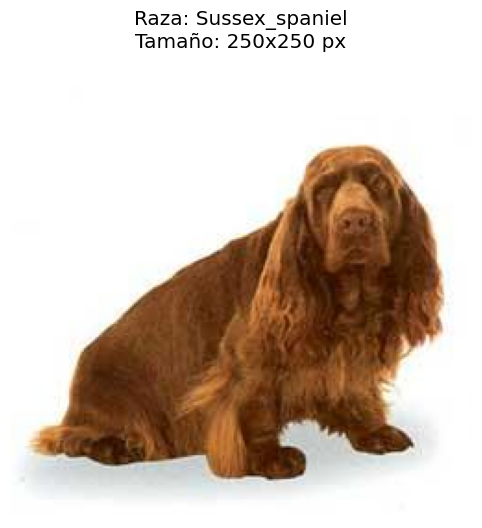

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from glob import glob
import random

# =============== 1. Cargar rutas e identificar razas ===============
ruta_base = r"C:\Users\facun\Desktop\TP imagenes\images\images"

# Buscar todas las imágenes dentro de subcarpetas (extensión .jpg)
imagenes = glob(os.path.join(ruta_base, "*", "*.jpg"))

# Crear DataFrame
df = pd.DataFrame({"path": imagenes})

# Extraer el nombre de la carpeta (ej: 'n02085620-Chihuahua')
df["folder_name"] = df["path"].apply(lambda x: os.path.basename(os.path.dirname(x)))

# Extraer la raza (parte después del guion)
df["Label"] = df["folder_name"].apply(lambda x: x.split("-", 1)[1] if "-" in x else x)

print(f"✅ Total de imágenes: {len(df)}")
print(f"🐾 Razas únicas: {df['Label'].nunique()}")
print(df.head())

# =============== 2. Función para leer imágenes en RGB ===============
def cv2_read_RGB(path):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(f"No se encontró la imagen: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# =============== 3. Seleccionar y mostrar una imagen ===============
# Elegir una imagen al azar
fila = df.sample(1).iloc[0]
ruta_img = fila["path"]
raza = fila["Label"]

print(f"\n📸 Mostrando imagen de la raza: {raza}")
print(f"Ruta: {ruta_img}")

# Leer la imagen en formato RGB
img = cv2_read_RGB(ruta_img)

# Ver tamaño (alto, ancho, canales)
print("Tamaño de la imagen:", img.shape)

# Mostrar imagen
plt.imshow(img)
plt.axis('off')
plt.title(f"Raza: {raza}\nTamaño: {img.shape[1]}x{img.shape[0]} px")
plt.show()


In [8]:
import os
import numpy as np
from skimage import io, transform
from tqdm import tqdm

# === Parámetros ===
x, y = 224, 224
ruta_base = r"C:\Users\facun\Desktop\TP imagenes\images\images"
carpeta_salida = r"C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas"

# Crear carpeta base si no existe
os.makedirs(carpeta_salida, exist_ok=True)

def resize_and_save(img_path, output_folder, x=224, y=224):
    try:
        img = io.imread(img_path)
        if img.ndim == 3 and img.shape[2] > 3:
            img = img[:, :, :3]
        if img.ndim == 2:
            img = np.stack((img,)*3, axis=-1)
        new_img = transform.resize(img, (x, y), anti_aliasing=True)

        # Mantener estructura por raza
        folder_name = os.path.basename(os.path.dirname(img_path))
        out_dir = os.path.join(output_folder, folder_name)
        os.makedirs(out_dir, exist_ok=True)

        nombre = os.path.basename(img_path)
        ruta_guardado = os.path.join(out_dir, nombre)
        io.imsave(ruta_guardado, (new_img * 255).astype(np.uint8))

    except Exception as e:
        print(f"⚠️ Error con {img_path}: {e}")

# === Ejecutar ===
from tqdm import tqdm
for ruta in tqdm(df["path"].tolist(), desc="Redimensionando imágenes"):
    resize_and_save(ruta, carpeta_salida, x, y)

print("\n✅ Proceso completado.")
print("Imágenes guardadas en:", carpeta_salida)




Redimensionando imágenes: 100%|██████████| 20580/20580 [13:37<00:00, 25.17it/s]


✅ Proceso completado.
Imágenes guardadas en: C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas


📸 Ejemplo: n02097130_262.jpg
Raza: giant_schnauzer
Tamaño: (224, 224, 3)


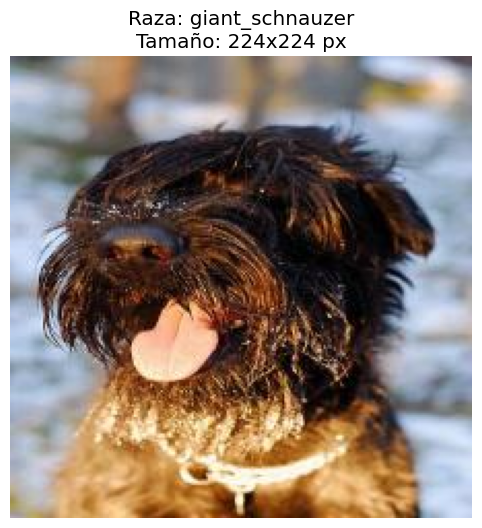

In [9]:
import os
import random
from skimage import io
import matplotlib.pyplot as plt

# Ruta base donde guardaste las imágenes redimensionadas
carpeta_salida = r"C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas"

# Buscar todas las subcarpetas (razas)
subcarpetas = [os.path.join(carpeta_salida, d) for d in os.listdir(carpeta_salida)
               if os.path.isdir(os.path.join(carpeta_salida, d))]

if not subcarpetas:
    raise FileNotFoundError(f"No se encontraron subcarpetas dentro de {carpeta_salida}. ¿Ejecutaste el paso de redimensionamiento?")

# Elegir una subcarpeta (raza) al azar
carpeta_raza = random.choice(subcarpetas)
raza = os.path.basename(carpeta_raza).split("-", 1)[1] if "-" in os.path.basename(carpeta_raza) else os.path.basename(carpeta_raza)

# Elegir una imagen dentro de esa raza
imagenes = [f for f in os.listdir(carpeta_raza) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
if not imagenes:
    raise FileNotFoundError(f"No hay imágenes en {carpeta_raza}")

ejemplo = random.choice(imagenes)
ruta_img = os.path.join(carpeta_raza, ejemplo)

# Leer y mostrar
img = io.imread(ruta_img)
print(f"📸 Ejemplo: {ejemplo}")
print(f"Raza: {raza}")
print("Tamaño:", img.shape)

plt.imshow(img)
plt.axis("off")
plt.title(f"Raza: {raza}\nTamaño: {img.shape[1]}x{img.shape[0]} px")
plt.show()




#2.   Generamos el df



In [10]:
import os
import pandas as pd
from glob import glob

ruta_base = r"C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas"

imagenes = glob(os.path.join(ruta_base, "*", "*.jpg")) + \
            glob(os.path.join(ruta_base, "*", "*.png")) + \
            glob(os.path.join(ruta_base, "*", "*.jpeg"))

df_resized = pd.DataFrame({"path": imagenes})
df_resized["filename"] = df_resized["path"].apply(os.path.basename)
df_resized["folder_name"] = df_resized["path"].apply(lambda x: os.path.basename(os.path.dirname(x)))
df_resized["Label"] = df_resized["folder_name"].apply(lambda x: x.split("-", 1)[1] if "-" in x else x)

print("✅ DataFrame generado correctamente")
print(df_resized.head())
print(f"\nTotal de imágenes: {len(df_resized)}")
print(f"Razas únicas: {df_resized['Label'].nunique()}")



✅ DataFrame generado correctamente
                                                path             filename  \
0  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620_10074.jpg   
1  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620_10131.jpg   
2  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620_10621.jpg   
3  C:\Users\facun\Desktop\TP imagenes\images\imag...   n02085620_1073.jpg   
4  C:\Users\facun\Desktop\TP imagenes\images\imag...  n02085620_10976.jpg   

           folder_name      Label  
0  n02085620-Chihuahua  Chihuahua  
1  n02085620-Chihuahua  Chihuahua  
2  n02085620-Chihuahua  Chihuahua  
3  n02085620-Chihuahua  Chihuahua  
4  n02085620-Chihuahua  Chihuahua  

Total de imágenes: 20580
Razas únicas: 120


Hago una selección de 15 razas al azar (200 imágenes de cada uno)
- Puedo probar sacar más muestras con otras semillas

In [11]:
import pandas as pd
import random

random.seed(42)

# Filtrar razas que tengan al menos 200 imágenes
razas_con_suficientes = df_resized["Label"].value_counts()
razas_validas = razas_con_suficientes[razas_con_suficientes >= 200].index.tolist()

# Seleccionar 15 razas al azar entre las válidas
razas_seleccionadas = random.sample(sorted(razas_validas), 15)

# Crear un nuevo DataFrame con máximo 200 imágenes por raza
df_list = []
for raza in razas_seleccionadas:
    subset = df_resized[df_resized["Label"] == raza]
    if len(subset) > 200:
        subset = subset.sample(200, random_state=42)
    df_list.append(subset)

df_15 = pd.concat(df_list).reset_index(drop=True)

print(f"✅ Se seleccionaron {len(razas_seleccionadas)} razas:")
print(razas_seleccionadas)
print(f"\nTotal de imágenes seleccionadas: {len(df_15)}")

# Resumen de cantidad por raza
print(df_15['Label'].value_counts())


✅ Se seleccionaron 15 razas:
['EntleBucher', 'Afghan_hound', 'Scottish_deerhound', 'Great_Pyrenees', 'pug', 'Sealyham_terrier', 'Bernese_mountain_dog', 'Airedale', 'Pomeranian', 'Saluki', 'Shih-Tzu', 'Tibetan_terrier', 'basenji', 'Leonberg', 'Irish_wolfhound']

Total de imágenes seleccionadas: 3000
Label
EntleBucher             200
Afghan_hound            200
Scottish_deerhound      200
Great_Pyrenees          200
pug                     200
Sealyham_terrier        200
Bernese_mountain_dog    200
Airedale                200
Pomeranian              200
Saluki                  200
Shih-Tzu                200
Tibetan_terrier         200
basenji                 200
Leonberg                200
Irish_wolfhound         200
Name: count, dtype: int64


Leyendo imágenes: 100%|██████████| 3000/3000 [00:30<00:00, 98.88it/s] 


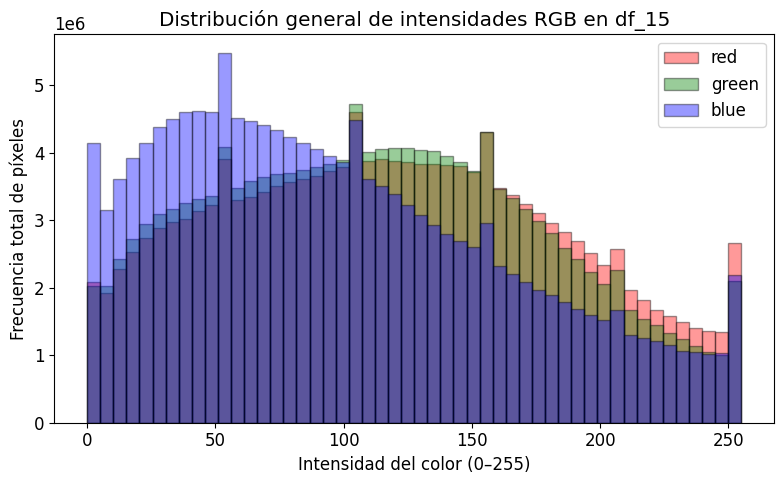

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from tqdm import tqdm

# --- Acumuladores para los tres canales ---
r_vals, g_vals, b_vals = [], [], []

# --- Recorrer todas las imágenes del df_15 ---
for path in tqdm(df_15["path"], desc="Leyendo imágenes"):
    try:
        img = io.imread(path)

        # Asegurarnos de que tenga 3 canales
        if img.ndim == 3 and img.shape[2] >= 3:
            # Si los valores están entre 0-1, los llevamos a 0-255
            if img.dtype != 'uint8':
                img = (img * 255).astype(np.uint8)
            
            # Guardamos intensidades por canal
            r_vals.extend(img[:, :, 0].flatten())
            g_vals.extend(img[:, :, 1].flatten())
            b_vals.extend(img[:, :, 2].flatten())
    except Exception as e:
        print(f"⚠️ Error con {path}: {e}")

# --- Graficar histograma general ---
plt.figure(figsize=(8, 5))
colores = ['red', 'green', 'blue']
valores = [r_vals, g_vals, b_vals]

for vals, cs in zip(valores, colores):
    plt.hist(vals, bins=50, color=cs, edgecolor='k', alpha=0.4, label=cs)

plt.legend()
plt.title("Distribución general de intensidades RGB en df_15")
plt.xlabel("Intensidad del color (0–255)")
plt.ylabel("Frecuencia total de píxeles")
plt.tight_layout()
plt.show()


Cuando analizamos la distribución RGB de todas las imágenes seleccionadas se observa que predomina la distribución de colores rojos y verdes, lo que indicaría una predominancia de tonalidades cálidas, como el marrón y el beige, característicos del pelaje de muchas razas incluidas en el conjunto.

In [12]:
# Instanciar la clase Clustimage
cl = Clustimage()

# Dimensión deseada (todas las imágenes deben tener el mismo tamaño)
x, y = 224, 224  # o el tamaño que usaste al redimensionar

# ===================== VECTORIZAR IMÁGENES =====================
# DataFrame para almacenar vectores
df_vectores = pd.DataFrame()

# Recorremos todas las rutas de df_15
for ruta in tqdm(df_15["path"], desc="Vectorizando imágenes"):
    try:
        # Leer y redimensionar la imagen
        img = cl.imread(ruta, dim=(x, y), colorscale=1)
        
        # Convertir la imagen en DataFrame (una fila)
        fila = pd.DataFrame(img).T
        
        # Concatenar al DataFrame general
        df_vectores = pd.concat([df_vectores, fila], ignore_index=True)
    
    except Exception as e:
        print(f"⚠️ Error con {ruta}: {e}")

# ===================== AÑADIR ETIQUETAS =====================
df_vectores["Label"] = df_15["Label"].values

print("✅ Vectorización completada.")
print(f"Total de imágenes procesadas: {len(df_vectores)}")
print(f"Dimensiones del DataFrame: {df_vectores.shape}")
df_vectores.head(3)

[05-11-2025 22:53:27] [clustimage.clustimage] filepath is set to [C:\Users\facun\AppData\Local\Temp\clustimage]
Vectorizando imágenes: 100%|██████████| 3000/3000 [06:36<00:00,  7.56it/s]


✅ Vectorización completada.
Total de imágenes procesadas: 3000
Dimensiones del DataFrame: (3000, 150529)


,0,1,2,3,4,5,6,7,8,9,...,150519,150520,150521,150522,150523,150524,150525,150526,150527,Label
0,188,179,176,196,187,184,211,202,199,226,...,179,182,186,186,189,193,178,181,185,EntleBucher
1,223,225,219,222,224,217,221,223,216,220,...,227,228,226,227,228,226,227,228,226,EntleBucher
2,29,87,82,30,88,83,43,97,92,56,...,130,102,85,130,102,85,130,102,85,EntleBucher


In [13]:
#para ver cantidad de columnas que tenemos
df_vectores.shape

(3000, 150529)

#3. Preprocesamiento de los datos

In [14]:
#nos fijamos si hay columnas con valores perdidos (no deberìa haber pero chequeamos por las dudas)
columnas_con_na = df_vectores.columns[df_vectores.isna().any()].tolist()

print("Columnas con al menos un NA:", columnas_con_na)

Columnas con al menos un NA: []


In [15]:
# Para verificar las columnas numéricas que estén entre 0 y 255

# ver si acá agregamos la columna name o solo label
columnas_numericas = df_vectores.drop(columns=['Label'])

# Verificar si al menos un valor está fuera del rango (0, 255) para cada columna
fuera_de_rango = ~((columnas_numericas >= 0) & (columnas_numericas <= 255))

# Filtrar las columnas que tienen al menos un valor fuera de rango
columnas_fuera_de_rango = fuera_de_rango.any()

# Obtener el nombre de las columnas que tienen valores fuera de rango
columnas_con_fuera_de_rango = columnas_fuera_de_rango[columnas_fuera_de_rango].index

# Imprimir las columnas con valores fuera de rango
for columna in columnas_con_fuera_de_rango:
    print(f'Columna {columna} tiene valores fuera de rango (0, 255)')

columnas_con_fuera_de_rango

Index([], dtype='object')

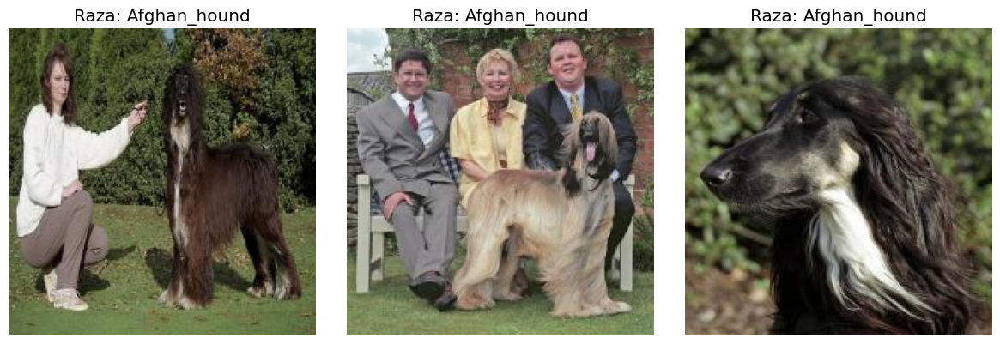

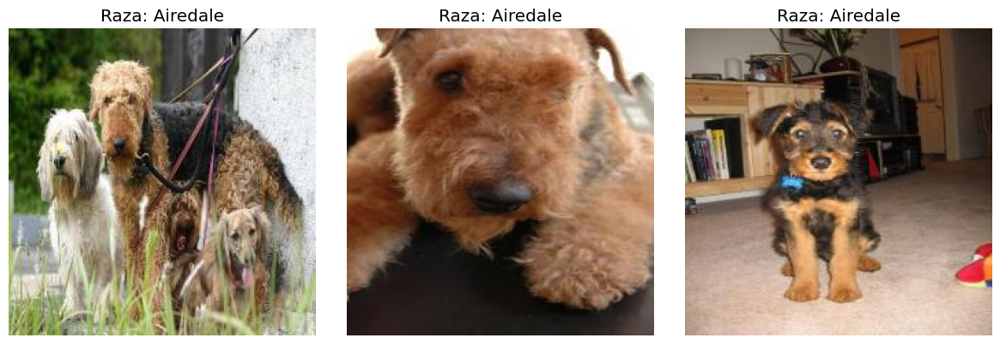

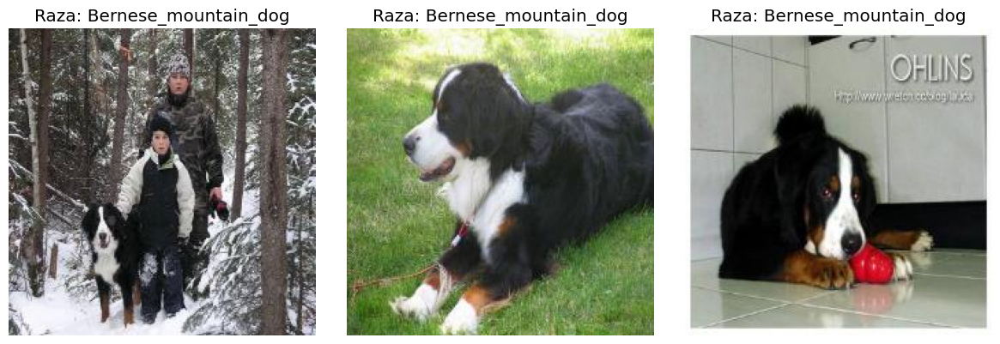

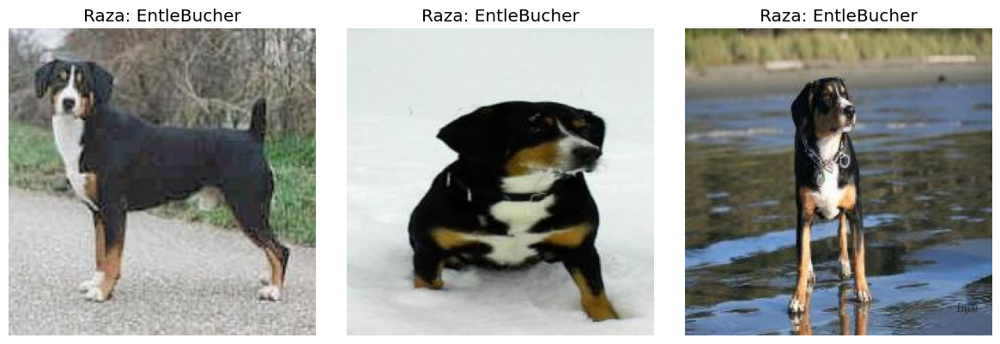

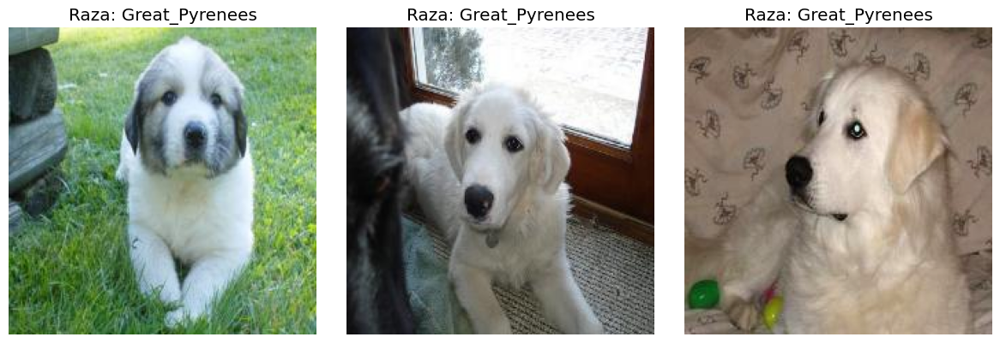

...

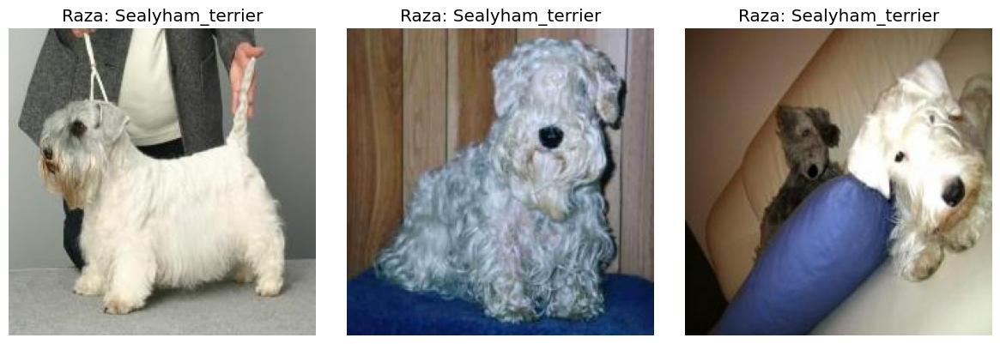

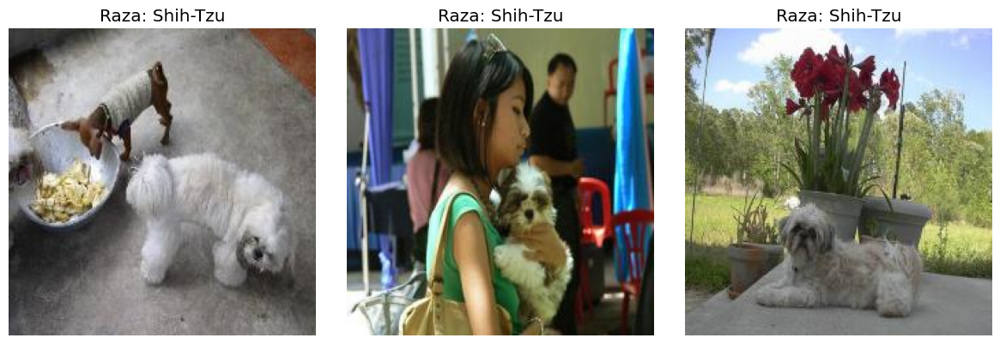

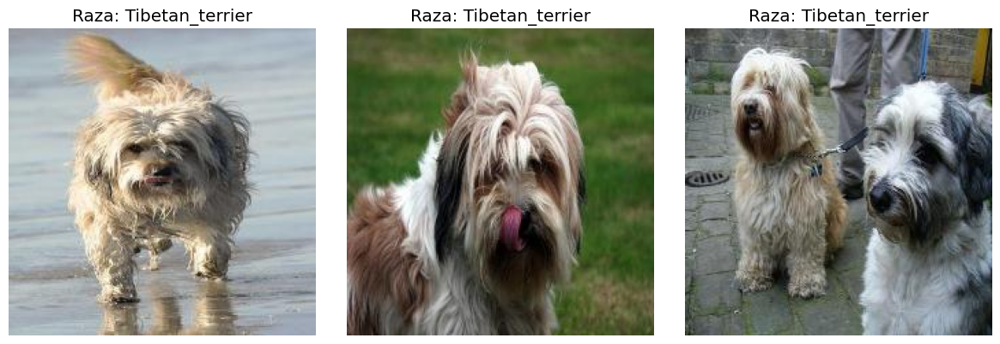

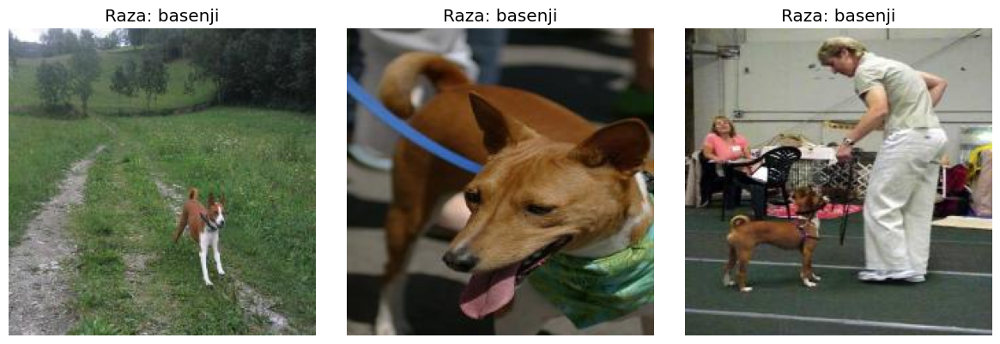

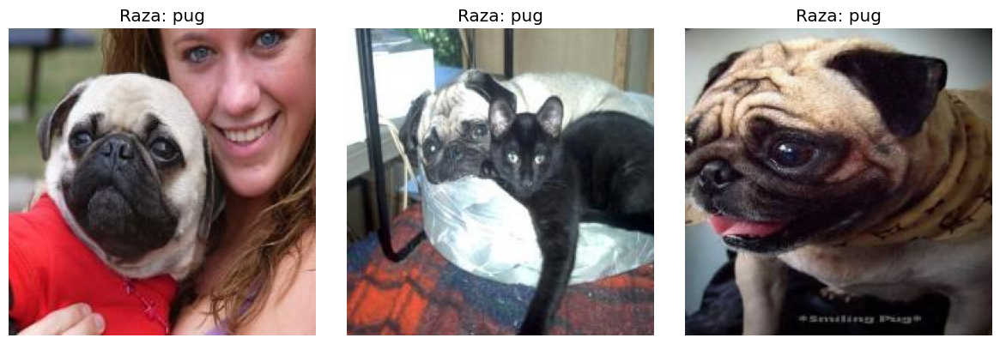

In [16]:
#graficamos algunas imágenes de cada una 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

primeras_img = df_vectores.groupby('Label').head(3)

for especie, grupo in primeras_img.groupby('Label'):
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))  # para que me genere una fila por especie y tres imágenes de cada una

    for i, (_, row) in enumerate(grupo.iterrows()):
        imagen = np.array(row.drop(['Label']), dtype=np.uint8).reshape(x, x, 3) #ver si hay que agregar name en el drop

        # Corrijo canales de color (de BGR a RGB) - en el de flores tuve que hacerlo
        imagen_rgb = np.flip(imagen, axis=-1)

        axs[i].imshow(imagen_rgb)
        axs[i].set_title(f"Raza: {especie}")
        axs[i].axis('off')

    plt.tight_layout()
    plt.show()


En esta pequeña muestra de imágenes de cada raza se observan que en algunas el perro no es el foco principal de la foto (ej.: el gato con el Pug) y que, probablemente, los modelos de clustering tengan dificultad en clasificarlas correctamente.

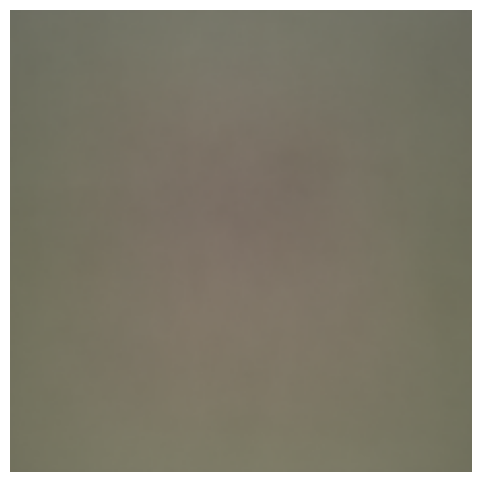

In [17]:
#calculamos la imagen promedio y la imagen promedio por especie para ver patrones de forma y color

df2= df_vectores.drop('Label', axis=1)

# Calcular el promedio de cada píxel
promedio_pixel = df2.mean(axis=0)  # Calcula el promedio a lo largo de todas las filas

imagen_promedio = promedio_pixel.values.reshape((x, x, 3))

# Cambiar el orden de los canales de BGR a RGB
imagen_rgb = imagen_promedio[:, :, ::-1]

# Mostrar la imagen promedio
plt.imshow(imagen_rgb.astype('uint8'))
plt.axis('off')
plt.show()


In [21]:
df2.columns

Index([     0,      1,      2,      3,      4,      5,      6,      7,      8,
            9,
       ...
       150518, 150519, 150520, 150521, 150522, 150523, 150524, 150525, 150526,
       150527],
      dtype='object', length=150528)

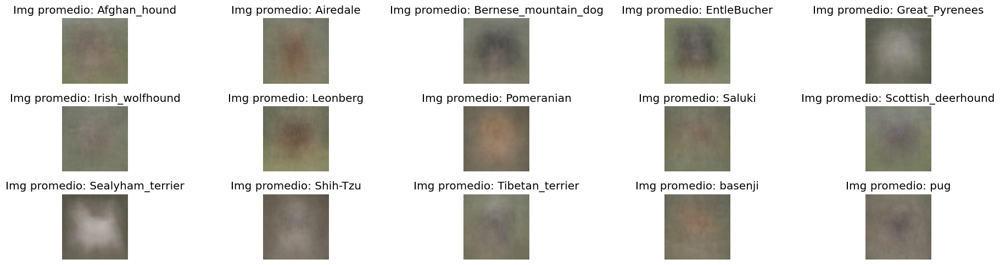

In [22]:
df2 = df_vectores.drop('Label', axis=1)

# Calcular el promedio por especie
promedio_por_especie = df_vectores.groupby('Label').mean()


# Crear una figura con dos filas y cinco columnas
fig, axs = plt.subplots(3, 5, figsize=(20, 5))

# Iterar sobre las especies y mostrar las imágenes
for idx, (especie, promedio) in enumerate(promedio_por_especie.iterrows()):
    imagen = promedio.values.reshape((x, y, 3))  # Corregimos la ubicación del reshape

    # Corregir la interpretación de los colores (invertir de BGR a RGB)
    imagen_rgb = imagen[:, :, ::-1]

    # Obtener las coordenadas del subgráfico actual
    fila = idx // 5
    columna = idx % 5

    # Mostrar la imagen resultante en el subgráfico correspondiente
    axs[fila, columna].imshow(imagen_rgb.astype('uint8'))
    axs[fila, columna].set_title(f'Img promedio: {especie}')
    axs[fila, columna].axis('off')

# Ajustar espaciado entre subgráficos
plt.tight_layout()
plt.show()

Solo en algunos casos, como en el Pomeranian y el Sealyham terrier, se observa que el promedio de los colores de las imágenes mantiene una forma y tonalidades parecidas a las de la raza.

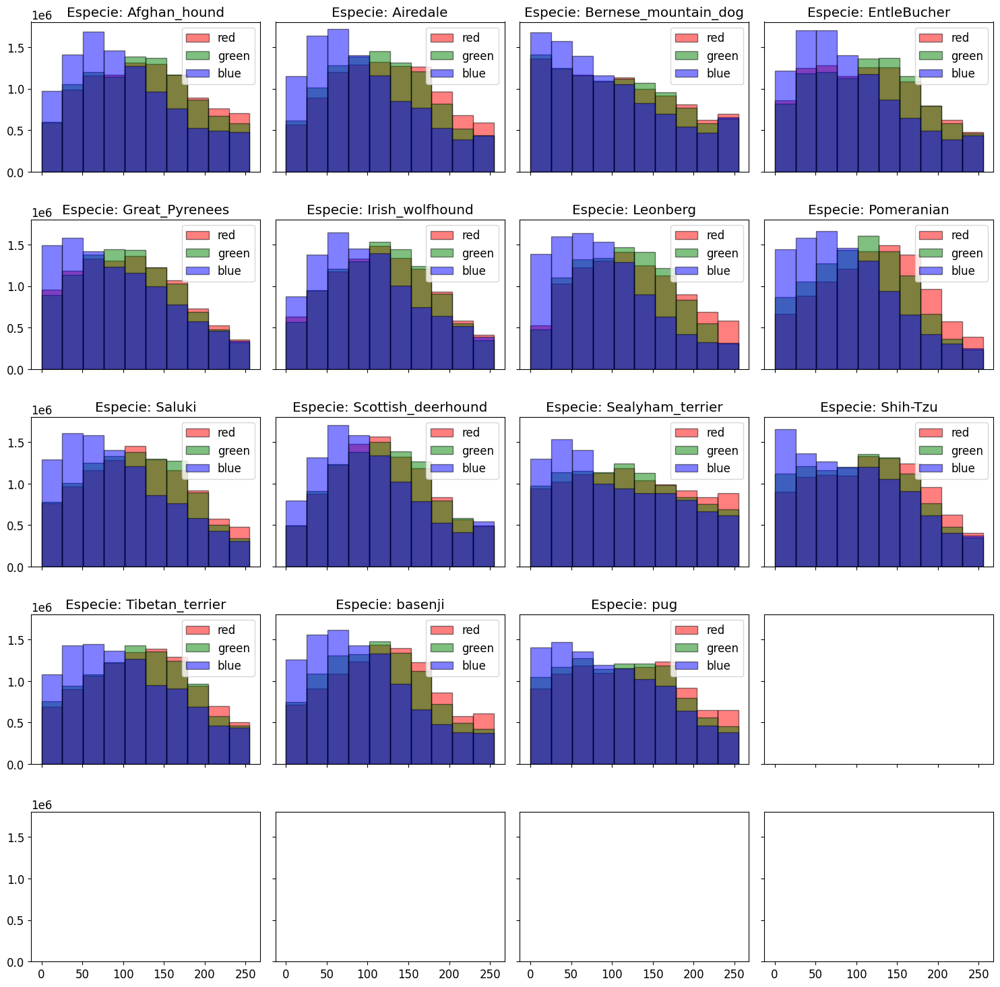

In [18]:
# --- Configuración ---
x, y = 224, 224
colores = ['red', 'green', 'blue']

# Crear diccionario para almacenar imágenes por raza
res = {}

# Asociar etiquetas y rutas correctamente
paths_with_labels = zip(df_15["Label"].tolist(), df_15["path"].tolist())

# Leer imágenes y agruparlas por especie
for label, p in paths_with_labels:
    try:
        img = cv2.imread(p)
        if img is None:
            raise FileNotFoundError(f"No se encontró la imagen: {p}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (x, y))
        
        # Acumular por especie
        if label not in res:
            res[label] = img
        else:
            res[label] = np.vstack((res[label], img))
    
    except Exception as e:
        print(f"⚠️ Error con {p}: {e}")

# --- Graficar histogramas ---
f, axs = plt.subplots(round(len(res)/4) + 1, 4, sharex=True, sharey=True, figsize=(15, len(res)))
axs = axs.flatten()

for i, label in enumerate(sorted(res)):
    img = res[label]
    axs[i].set_title(f'Especie: {label}')
    for n, cs in enumerate(colores):
        monocol = img[:, :, n]
        axs[i].hist(monocol.flatten(), color=cs, bins=10, edgecolor='k', alpha=0.5, label=cs, range=(0, 255))
    axs[i].legend()

plt.tight_layout()
plt.show()

Al igual que el histogrma de todo el conjunto de imágenes, los colores que predominan, por ejemplo, para en las razas Pug, Pomeranian y Basenji, son el rojo y verde, lo que indica pelajes marrones o anaranjados. En cambio, para razas como Scottish deerhound o Great Pyrenees presentan una distribución más equilibrada, con mayor presencia del azul, lo que sugiere tonos fríos o grises.

In [19]:
df_vectores.shape

(3000, 150529)

In [20]:
import pickle
#guardo el df en un archivo pickle
# Evitar el error de escape en Windows paths usando raw string (o duplicando backslashes).
# No reimportamos `pickle` para no duplicar imports si ya fue importado en otra celda.
ruta_guardado_pickle = r"C:\Users\facun\Desktop\TP imagenes\df_preprocesado.pkl"

with open(ruta_guardado_pickle, 'wb') as archivo:
    pickle.dump(df_vectores, archivo)

In [25]:
#si lo quiero levantar
#df=pd.read_pickle(r"C:\Users\facun\Desktop\TP imagenes\df_preprocesado.pkl")

#4. Extracción de características / features

In [21]:
!pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\facun\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [22]:
# Ensure TensorFlow (which provides keras) is installed in the kernel
%pip install -q tensorflow

# for loading/processing the images and VGG model (use tensorflow.keras)
from tensorflow.keras.applications.vgg16 import preprocess_input, VGG16
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.models import Model

# clustering and dimension reduction
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [23]:
model = VGG16()
model = Model(inputs = model.inputs, outputs = model.layers[-2].output)

In [24]:
def extract_features(file, model):
    # levanta imagen como array
    img = load_img(file, target_size=(224,224))
    # convierte img a numpy array (originalmente es 'PIL.Image.Image')
    img = np.array(img)
    # reshape para tener formato necesario para el modelo (num_of_samples, dim 1, dim 2, channels)
    reshaped_img = img.reshape(1,224,224,3)
    # prepara imagen para modelo (función de keras)
    imgx = preprocess_input(reshaped_img)
    # extrae features
    features = model.predict(imgx)
    return features

In [25]:
def preprocess(lista, model):
    datays = {}
    for i in lista:
      print(i)
      featuress = extract_features(i, model)
      datays[i] = featuress
    # lista de filenames
    filenmss = np.array(list(datays.keys()))

    # lista de features
    featsss = np.array(list(datays.values()))

    # reshape 4096 features por el número de imágenes
    print(featsss.shape)
    featsss = featsss.reshape(-1, 4096)
    return filenmss, featsss

In [26]:
model.input_shape

(None, 224, 224, 3)

In [27]:
# function that lets you view a cluster (based on identifier)
def view_cluster(gps,cluster):
    plt.figure(figsize = (25,25));
    # gets the list of filenames for a cluster
    files = gps
    # only allow up to 30 images to be shown at a time
    if len(files) > 10:
        print(f"Clipping cluster size from {len(files)} to 10")
        files = files[:9]
    # plot each image in the cluster
    for index, file in enumerate(files):
        plt.subplot(1,10,index+1);
        img = load_img(file)
        img = np.array(img)
        plt.imshow(img)
        plt.title('Cluster n:' + str(cluster))
        plt.axis('off')

In [28]:
# Levanta archivos y extrae features
# Usar la lista de rutas generada en df_15
if 'df_vectores' in globals():
	lista_paths = df_15["path"].tolist()
else:
	raise NameError("df_15 no está definido. Ejecuta la celda que genera df_15 antes de esta.")
names, feat = preprocess(lista_paths, model)

C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_2573.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_1226.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_1482.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_3682.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_841.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_2987.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
C:\Users\facun\Desktop\TP imagenes\images\imagenes_redimensionadas\n02108000-EntleBucher\n02108000_215.jpg
1/1 ━━━━━━━━

In [29]:
import pickle

# Guardar el DataFrame usando pickle
ruta_pickle = r"C:\Users\facun\Desktop\TP imagenes\features.pkl"

# Guardar el DataFrame usando pickle
with open(ruta_pickle, 'wb') as archivo:
    pickle.dump(feat, archivo)

In [30]:
feat

array([[0.        , 0.        , 4.372762  , ..., 0.        , 0.8560434 ,
        0.        ],
       [0.        , 0.        , 0.5063461 , ..., 0.99456286, 3.7904382 ,
        0.        ],
       [0.        , 0.        , 2.2488313 , ..., 0.        , 1.1731006 ,
        0.7874066 ],
       ...,
       [7.7246966 , 0.08614656, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [6.4491067 , 2.1382682 , 1.4545326 , ..., 0.        , 3.6090364 ,
        0.37130788],
       [5.4865913 , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

In [36]:
#si lo quiero levantar
#feat=pd.read_pickle(/content/drive/MyDrive/EDA-2025/Semana 9/features.pkl")

In [31]:
pca = PCA(n_components=200, random_state=22)
pca.fit(feat)
x = pca.transform(feat)

In [32]:
print(f"Components before PCA: {feat.shape[1]}")
print(f"Components after PCA: {pca.n_components}")

Components before PCA: 4096
Components after PCA: 200


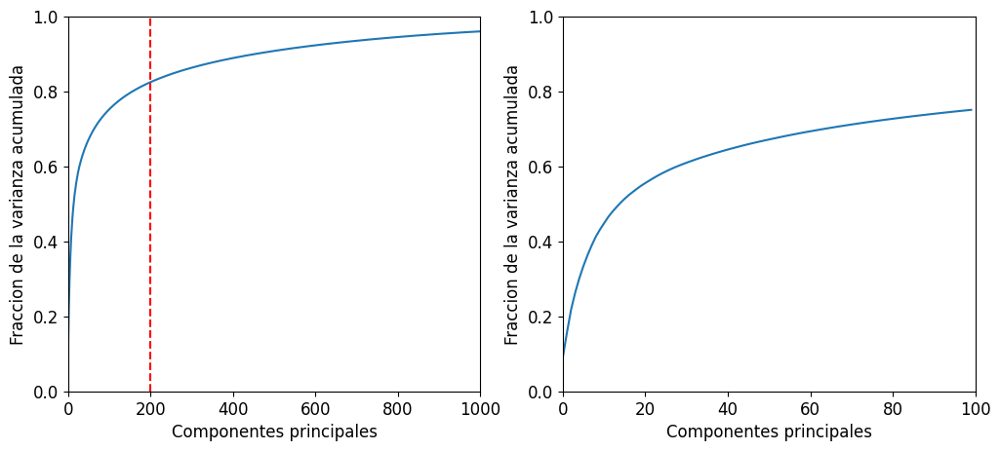

In [33]:
#Celda para mostrar cuánto de la varianza estamos tomando
pca0 = PCA(n_components=1000, random_state=22)
pca0.fit(feat)
fig,ax=plt.subplots(1,2,figsize=(12,5))
ax[0].plot(range(0,1000),[0]+np.cumsum(pca0.explained_variance_ratio_))
ax[0].axvline(x=200,c="r",linestyle="--")
ax[0].set_ylim(0,1)
ax[0].set_xlim(0,1000)
ax[0].set_ylabel("Fraccion de la varianza acumulada")
ax[0].set_xlabel("Componentes principales")
pca1 = PCA(n_components=100, random_state=22)
pca1.fit(feat)
ax[1].plot(range(0,100),[0]+np.cumsum(pca1.explained_variance_ratio_))
ax[1].set_ylim(0,1)
ax[1].set_xlim(0,100)
ax[1].set_ylabel("Fraccion de la varianza acumulada")
ax[1].set_xlabel("Componentes principales")
#plt.savefig(image_path+"/../../principal_components_variance.png")
plt.show()

In [35]:
# Calcular y mostrar la varianza acumulada para los 200 componentes ya ajustados en `pca`
cum_var = np.cumsum(pca.explained_variance_ratio_)

# Imprimir el total acumulado y algunos valores intermedios
print(f"Varianza acumulada con 200 componentes: {cum_var[-1]:.6f} ({cum_var[-1]*100:.2f}%)")

Varianza acumulada con 200 componentes: 0.823548 (82.35%)


In [36]:
import pickle

# Guardar el DataFrame usando pickle
ruta_pickle = r"C:\Users\facun\Desktop\TP imagenes\df_pca.pkl"

# Guardar el DataFrame usando pickle
with open(ruta_pickle, 'wb') as archivo:
    pickle.dump(x, archivo)

https://www.researchgate.net/publication/352846889_DCNN-Based_Vegetable_Image_Classification_Using_Transfer_Learning_A_Comparative_Study)


In [41]:
#Leer el pickle
#x=pd.read_pickle("/content/drive/MyDrive/EDA-2025/Semana 9/df_pca.pkl")

In [37]:
#levantamos el df en un archivo pickle
import pickle

ruta_guardado_pickle = r"C:\Users\facun\Desktop\TP imagenes\df_preprocesado.pkl"

with open(ruta_guardado_pickle, 'wb') as archivo:
    pickle.dump(df_vectores, archivo)

In [38]:
df_vectores.shape

(3000, 150529)

In [39]:
df_vectores

,0,1,2,3,4,5,6,7,8,9,...,150519,150520,150521,150522,150523,150524,150525,150526,150527,Label
0,188,179,176,196,187,184,211,202,199,226,...,179,182,186,186,189,193,178,181,185,EntleBucher
1,223,225,219,222,224,217,221,223,216,220,...,227,228,226,227,228,226,227,228,226,EntleBucher
2,29,87,82,30,88,83,43,97,92,56,...,130,102,85,130,102,85,130,102,85,EntleBucher
3,172,246,240,182,254,248,178,245,240,167,...,191,165,153,190,163,153,208,181,171,EntleBucher
4,45,42,44,48,44,47,49,44,50,48,...,194,194,194,197,197,197,205,205,205,EntleBucher
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,91,159,134,94,162,137,94,162,139,89,...,58,135,101,73,148,114,89,163,129,Irish_wolfhound
2996,21,27,9,19,25,7,15,22,4,14,...,14,19,7,26,26,9,27,26,5,Irish_wolfhound
2997,25,103,72,23,103,72,23,106,74,28,...,58,108,74,54,96,79,67,104,94,Irish_wolfhound
2998,107,124,150,139,154,180,110,124,147,155,...,19,30,44,20,29,42,20,29,42,Irish_wolfhound


### I. TENDENCIA AL CLUSTERING: ÍNDICE DE HOPKINS
(código tomado de https://matevzkunaver.wordpress.com/2017/06/20/hopkins-test-for-cluster-tendency/)

El método de Hopkins consiste en generar p puntos distribuidos al azar en el espacio muestral, y además extraer p puntos reales del dataset. Luego se calculan las distancias a los vecinos más próximos dentro del subconjunto de datos generados al azar (u) y dentro del subconjunto de datos extraídos del dataset (w), con estos se calcula el coeficiente de Hopkins (H). Si los nuevos puntos están igual de alejados que los tomados al azar, entonces sum(u) ~ sum(w) y H ~ 0.5. En cambio, si sum(u) >> sum(w), es decir que en promedio están menos agrupados los que se encuentran al azar, entonces H << 0.5.

In [40]:
from sklearn.neighbors import NearestNeighbors
from random import sample
from numpy.random import uniform
import numpy as np
from math import isnan

def hopkins(x):
    if isinstance(x, np.ndarray):
        d = x.shape[1]
        n = x.shape[0] # rows
    elif isinstance(x, pd.DataFrame):
        d = x.shape[1]
        n = len(x) # rows
    else:
        raise ValueError("Input should be a NumPy array or a pandas DataFrame")

    m = int(0.1 * n) # heuristic from article [1]
    nbrs = NearestNeighbors(n_neighbors=1).fit(x)

    rand_X = sample(range(0, n, 1), m)

    ujd = []
    wjd = []
    for j in range(0, m):
        u_dist, _ = nbrs.kneighbors(uniform(np.amin(x,axis=0),np.amax(x,axis=0),d).reshape(1, -1), 2, return_distance=True)
        ujd.append(u_dist[0][1])
        w_dist, _ = nbrs.kneighbors(x[rand_X[j]].reshape(1, -1), 2, return_distance=True)
        wjd.append(w_dist[0][1])

    H = sum(ujd) / (sum(ujd) + sum(wjd))
    if isnan(H):
        print(ujd, ujd)
        H = 0
    return H

In [41]:
print(f"El coeficiente de cluster de Hopkins sobre nuestro dataset es {hopkins(x):.2f}")

El coeficiente de cluster de Hopkins sobre nuestro dataset es 0.76


El índice de Hopkins es de 0.77 por lo que los datos poseen una tendencia a la clusterización y por tal motivo se procede al análisis y comparación de distintas técnicas de clustering

## II. EXPLORACIÓN: CLUSTERING JERARQUICO

A modo exploratorio, se aplica la técnica de clustering jerárquico aglomerativo. Se utiliza la matriz de distancia Euclídea, dado que solo se trabaja con datos contínuos y naturalmente normalizados ya que varían entre 0 y 255. Como complemento se calcula el índice cofenético para determinar el método a aplicar.

In [42]:
# Clustering (scipy)
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist, squareform
from scipy.cluster import hierarchy

In [43]:
# Cluster jerárquico: función para calcular el índice cofenético de cada método
def Jerarquico(metodos, df_vectores, d): # lista de métodos, datos y matriz de distancia
    for i in metodos: # cada elemento de la lista de métodos
        z = linkage(d, i) # cluster jerárquico
        c, coph_dists = cophenet(z, pdist(df_vectores)) # cálculo del índice cofenético
        print("Índice cofenético para el método "+i+":",round(c,3))

In [44]:
# la lista de métodos disponibles en la librería scipy
metodo = ["single","complete","average","weighted","centroid","median","ward"]

In [45]:
d_meta = squareform(pdist(x, 'euclidean'))

In [46]:
# Índices cofenéticos para el dataset con distancia euclídea
Jerarquico(metodo, x, d_meta)

Índice cofenético para el método single: 0.525
Índice cofenético para el método complete: 0.571
Índice cofenético para el método average: 0.663
Índice cofenético para el método weighted: 0.556
Índice cofenético para el método centroid: 0.64
Índice cofenético para el método median: 0.399
Índice cofenético para el método ward: 0.564


El método con mayor índice cofenético es el método "average", con un valor de 0.663. Para el cálculo del dendograma se considera entonces la matriz de distancia euclídea y el método **average**.

<Figure size 1000x600 with 0 Axes>

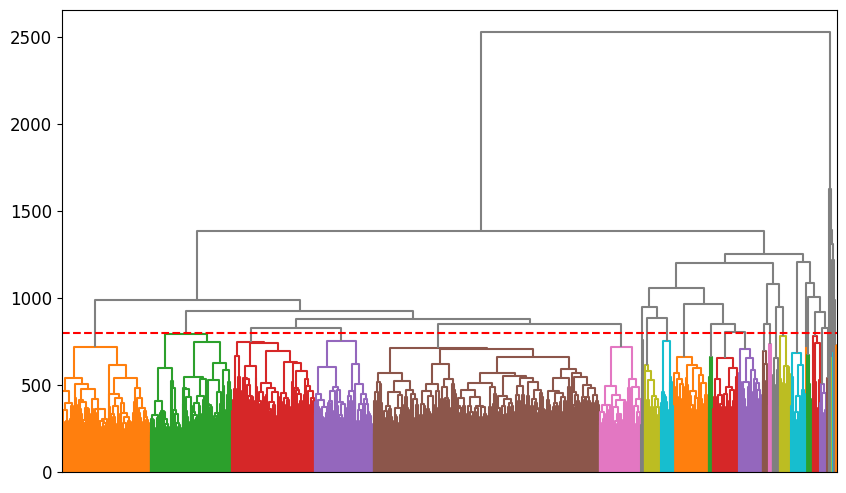

<Figure size 1000x600 with 0 Axes>

In [47]:
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import squareform

# Dendrograma para el dataset completo, distancia euclídea y método "average"
z_df = linkage(d_meta, "average")

hierarchy.dendrogram(z_df, color_threshold=800, above_threshold_color='grey',no_labels=True)
plt.axhline(y=800, color='r', linestyle='--')
plt.figure()


Se observa que este método distingue más de 15 grupos y uno de los cluster abarca muchas de las observaciones.

Definimos la cantidad de cluster según la cantidad de razas que se están analizando, es decir, 15

In [48]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
k = 15
clusters = fcluster(z_df, 15, criterion='maxclust', depth=15)

print(clusters)
print(set(clusters))

[1 1 1 ... 3 3 3]
{np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15)}


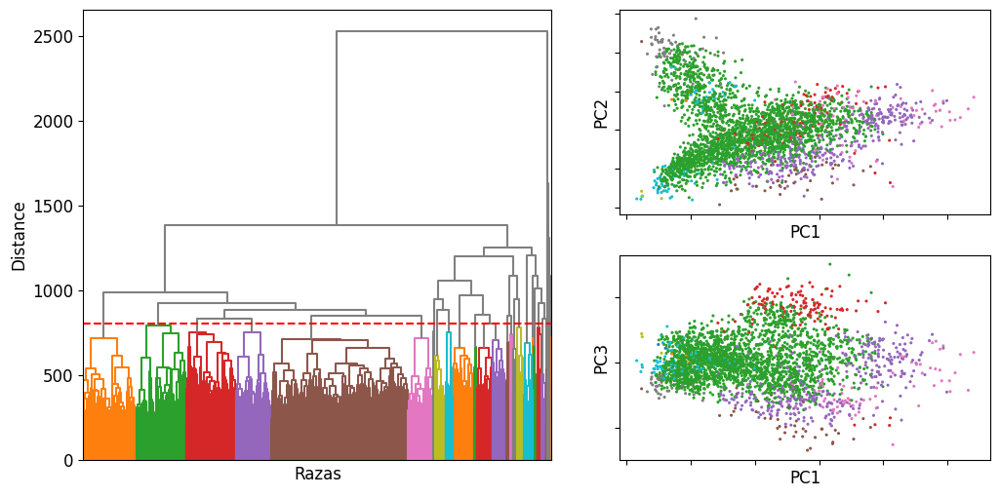

In [49]:
#Celda para hacer figura
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
gs1 = gridspec.GridSpec(2,2)
gs1.update(left=0.6, right=0.98, wspace=0.05)
ax1 = plt.subplot(gs1[0, :])
ax2 = plt.subplot(gs1[1, :],sharex=ax1)

gs2 = gridspec.GridSpec(1, 1)
gs2.update(left=0.05, right=0.53, hspace=0.05)
ax4 = plt.subplot(gs2[0,0])
#ax4.set_aspect('equal', adjustable='box')
plt.setp(ax2.get_xticklabels(), visible=False)
plt.setp(ax1.get_xticklabels(), visible=False)
plt.setp(ax2.get_yticklabels(), visible=False)
plt.setp(ax1.get_yticklabels(), visible=False)

colorlist=['tab:blue','tab:orange','tab:green','tab:red',
'tab:purple','tab:brown','tab:pink','tab:gray','tab:olive','tab:cyan','tab:blue','tab:orange','tab:green','tab:red',
'tab:purple','tab:brown','tab:pink','tab:gray','tab:olive','tab:cyan','tab:blue','tab:orange','tab:green','tab:red']
clustfactor=[colorlist[a+1] for a in clusters]
ax1.scatter(x[:,0],x[:,1],c=clustfactor,s=1.5)
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")

ax2.scatter(x[:,0],x[:,2],c=clustfactor,s=1.5)
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC3")


hierarchy.dendrogram(z_df, color_threshold=800, above_threshold_color='grey',no_labels=True,ax=ax4)
plt.axhline(y=800, color='r', linestyle='--')
ax4.set_xlabel("Razas")
ax4.set_ylabel("Distance")

#plt.savefig(image_path+"/../../hierarchical_dendrogram_and_projections.png",bbox_inches='tight')
plt.show()


#### Validación externa

##### Matriz de confusión

In [50]:
clase = df_vectores['Label'] #verdaderas etiquetas

In [51]:
ct_jerarq = pd.crosstab(clase,clusters)
ct_jerarq

col_0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Label,,,,,,,,,,,,,,,
Afghan_hound,99,0,79,0,14,0,0,0,0,0,0,4,4,0,0
Airedale,150,46,1,0,0,0,0,0,0,0,3,0,0,0,0
Bernese_mountain_dog,182,0,0,0,0,17,0,0,0,0,0,0,0,1,0
EntleBucher,163,0,0,0,0,37,0,0,0,0,0,0,0,0,0
Great_Pyrenees,179,0,17,3,0,0,0,0,0,0,0,0,1,0,0
Irish_wolfhound,139,0,55,0,6,0,0,0,0,0,0,0,0,0,0
Leonberg,65,0,98,36,0,0,0,0,0,0,0,0,0,0,1
Pomeranian,165,0,0,0,0,0,0,35,0,0,0,0,0,0,0
Saluki,158,0,3,0,31,0,0,0,0,0,0,0,8,0,0


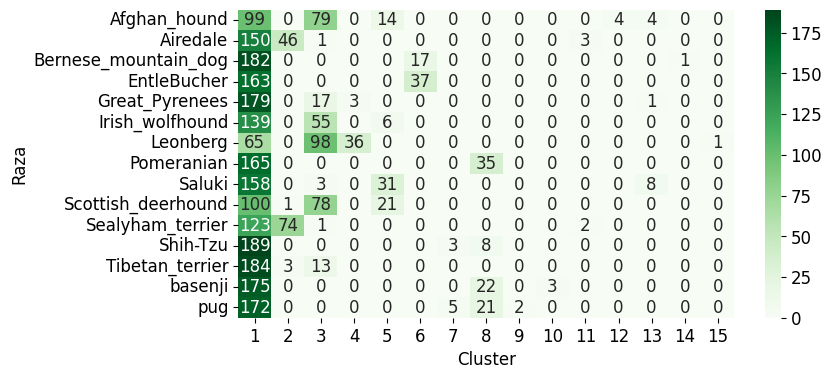

In [52]:
import seaborn as sns
plt.figure(figsize=(8,4))
sns.heatmap(ct_jerarq,cmap='Greens',annot=True,fmt='g')
plt.xlabel("Cluster")
plt.ylabel("Raza")
#plt.savefig(image_path+"/../../hierarchical_confusion_matrix.png")
plt.show()

Lo que se aprecia en la matriz es que, aunque se definieron 15 clusters, la mayor parte de las imágenes observadas se concentraron  en el cluster 1. Esto sugiere que, según las características utilizadas para el clustering jerárquico, el modelo no logró diferenciar visualmente entre las distintas razas, sino que las percibe como pertenecientes a conjunto de imágenes con rasgos comunes, por ejemplo, color del perro, el tamaño en la foto o el entorno (vimos anteriormente que hay fotos donde aparecen personas u objetos que pueden confundir al algoritmo al momento de clasificar en grupos).

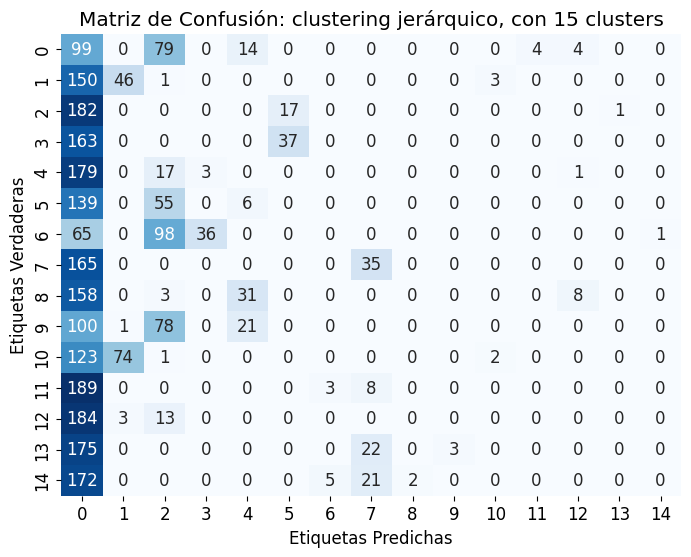

In [53]:
#otra visualización:

import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(ct_jerarq, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(15), yticklabels=range(15))
plt.xlabel('Etiquetas Predichas')
plt.ylabel('Etiquetas Verdaderas')
plt.title("Matriz de Confusión: clustering jerárquico, con 15 clusters")
plt.show()

#### índices que evalúan la calidad del clustering cuando existe una clasificación de referencia

##### Índice de Van Dongen

Varía entre cero y uno. Un valor cercano a cero en el índice de Van Dongen significa que existe un buen ajuste del clustering respecto a las etiquetas reales, mientras que un valor cercano a 1 indica que el clustering es diferente a las etiquetas reales.

In [55]:
#función que utilizaremos para distintos métodos
def vanDongen(ct):
    n2=2*(sum(ct.apply(sum,axis=1)))
    sumi = sum(ct.apply(np.max,axis=1))
    sumj = sum(ct.apply(np.max,axis=0))
    maxsumi = np.max(ct.apply(sum,axis=1))
    maxsumj = np.max(ct.apply(sum,axis=0))
    vd = (n2 - sumi - sumj)/(n2 - maxsumi - maxsumj)
    return vd

In [56]:
print(f"Van Dongen para Clustering Jerárquico Aglomerativo: {vanDongen(ct_jerarq)}")

Van Dongen para Clustering Jerárquico Aglomerativo: 0.8987911161090807


##### Índice Rand Ajustado

Su rango va de –1 a 1: los valores cercanos a 1 indican una coincidencia casi perfecta entre los clusters obtenidos y las etiquetas reales; los valores próximos a 0 reflejan una asociación equivalente al azar; y los valores negativos señalan una discordancia sistemática, es decir, una correspondencia peor que la que se esperaría por casualidad.

In [57]:
adjusted_rand_score (clase,clusters)

0.018853090850358637

**Conclusiones**: Dado que el índice de Van Dongen tiende a 1 y el índice de Rand ajustado se aproxima a 0, se interpreta que la clasificación obtenida mediante el clustering es muy diferente de las etiquetas reales, es decir, el modelo no logró reproducir la estructura original de las razas presentes en los datos.

## III. k-MEANS

El método de agrupamiento no supervisado conocido como K-means tiene como objetivo particionar un conjunto de n observaciones en k grupos, en los cuales los datos se agrupan de tal manera que los puntos en el mismo clúster sean más similares entre sí que los puntos en otros clusters. Un aspecto esencial para implementar este algoritmo es determinar adecuadamente el número de agrupamientos (k). 
En este informe, se determinó este valor utilizando dos técnicas: el "método del codo", que implica graficar la suma de los errores cuadrados (SSE) en función de k. Este método es heurístico y busca seleccionar la cantidad de grupos de manera que la adición de uno más no reduzca de manera significativa la varianza explicada. 
Ya que esta metodología puede resultar poco clara en ocasiones, se complementa con la técnica de validación interna de silhouette, en la cual se calcula y grafica el coeficiente de silhouette para diferentes cantidades de grupos. Este coeficiente es una medida de cuán similares son los datos dentro de un grupo en comparación con otros clústers. Un valor cercano a 1 indica que los datos dentro de un grupo son muy similares pero muy diferentes a los de otros grupos. Se considera k adecuado aquel que minimiza SSE y maximiza el índice de silhouette. 
Sin embargo, dado que estos valores no siempre coinciden, se busca un compromiso entre ambas condiciones.
En nuestro caso, al tener la cantidad de clases de razas de perros (15) se utilizaron ambos coeficientes de validación interna para determinar si el número óptimo de clusters coincide con la cantidad de clases.

Como método de validación externa, se utilizó la matriz de confusión y los índices de Van Dongen y Rand como métodos de comparación de los clusters obtenidos con las verdaderas clases.

Funciones a utilizar:

In [58]:
# Funciones para KMeans
# Silhouette Index: Función para calcularlo para cada número de clusters con KMeans
def SilIndex1(maxClusters,df):
    silI = [] # lista de índice
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMeans(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        sil_avg = silhouette_score(df, modelo.labels_) # calcular el índice Silhouette promedio de todo
        silI.append(sil_avg)
        print("Silhouette index (promedio) para "+str(i)+" clusters: ",round(sil_avg,3)) #imprime el resultado
        cluster_labels = modelo.labels_ # Las etiquetas de los clusters
        n_clusters=i # La cantidad de clusters
        sample_sil_values = silhouette_samples(df, modelo.labels_) # Los valores de SilIndex para cada registro
        for j in range(n_clusters): # Itera en la cantidad de clusters armados
            jth_cluster_sil_values = sample_sil_values[cluster_labels == j] # Los valores de SilIndex para el cluster J
            jth_cluster_sil_avg = np.mean(jth_cluster_sil_values) # El promedio de valores de SilIndex para el cluster J
            print("Silhouette index para el cluster "+str(j)+":", round(jth_cluster_sil_avg,3)) # imprime los resultados
        print() # imprime un espacio al final
    plt.plot(range(2, maxClusters), silI, color="Grey") # Gráfico
    #plt.title('Método del bastón roto')
    plt.xlabel('Cantidad de clusters')
    plt.ylabel('Índice Silhouette')
    plt.show()
    print(silI)


# Método del bastón roto: Función para realizarlo roto con el KMeans
def Baston1(maxClusters,df):
    sse = [] # Lista de los errores
    for i in range(1, maxClusters): # Itera entre 1 y el número máximo de clusters deseados
        modelo = KMeans(n_clusters=i, random_state=55)
        modelo.fit(df) # Fitea el modelo
        sse.append(modelo.inertia_) # Agrega el resultado a la lista
    plt.plot(range(1, maxClusters), sse, color="Grey") # Gráfico
    plt.axvline(x=15,ymin=0,ymax=1,c="r",linestyle="--")
    plt.title('Método del bastón roto')
    plt.xlabel('Cantidad de clusters')
    plt.ylabel('SSE')
    #plt.savefig(image_path+f"/../../elbow_plot_{maxClusters}.png")
    plt.show()

    print(sse)


# Gráfico de Silhouette: función para graficarlo por cada número de clusters con KMeans
def GrafSil1(maxClusters,df):
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMeans(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        sil_avg = silhouette_score(df, modelo.labels_) # calcular el índice Silhouette promedio de todo

        cluster_labels = modelo.labels_ # Las etiquetas de los clusters
        n_clusters=i # La cantidad de clusters
        sample_sil_values = silhouette_samples(df, modelo.labels_)

        fig, ax1 = plt.subplots(1, 1)
        fig.set_size_inches(10, 6)

        ax1.set_xlim([-0.1, 1])
        ax1.set_ylim([0, len(df) + (n_clusters + 1) * 10])

        y_lower = 10
        for j in range(n_clusters):
            jth_cluster_sil_values = sample_sil_values[cluster_labels == j]
            jth_cluster_sil_avg = np.mean(jth_cluster_sil_values)
            jth_cluster_sil_values.sort()
            size_cluster_j = jth_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_j

            #color = cm.nipy_spectral(float(j) / n_clusters)
            color = cmRoyal(float(j) / n_clusters)
            ax1.fill_betweenx(np.arange(y_lower, y_upper),
                              0, jth_cluster_sil_values,
                              facecolor=color, edgecolor=color, alpha=0.7)

            # Marcar los graficos de Silhouette con el numero de cluster
            ax1.text(-0.05, y_lower + 0.5 * size_cluster_j, str(j))

            # Marcar los graficos de Silhouette con el Silhuette promedio del cluster
            ax1.text(0.6, y_lower + 0.5 * size_cluster_j, str(round(jth_cluster_sil_avg,3)))

            # Calcular donde comenzar el proximo grafixo
            y_lower = y_upper + 10 # Marco una distancia de 10 entre graficos para que haya un espacio

        ax1.set_xlabel("Coeficiente de silhouette")
        ax1.set_ylabel("Cluster label")

        # La linea vertical es el Silhouette promedio
        ax1.axvline(x=sil_avg, color="red", linestyle="--")

        ax1.set_yticks([])
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        #plt.savefig(image_path+f"/../../silhouette_plot_{maxClusters}.png")
        plt.show()


# Matríz de confusión: función para realizarla por cada número de clusters con KMeans
def CM1(maxClusters,df):
    for i in range(2, maxClusters): # Itera entre 1 y el número máximo de clusters deseados
        modelo = KMeans(n_clusters=i, random_state=55).fit(df)
        cluster_labels = modelo.labels_
        tmp = pd.DataFrame({'Labels': clase, 'Clusters': modelo.labels_})# Crear un DataFrame con Labels y Clusters como columnas
        ct = pd.crosstab(tmp['Labels'], tmp['Clusters']) # Crea una matriz de confusion
        print(ct)
        print()


# Adjusted Rand Index: función para calcularlo para cada número de clusters con KMeans
def RandIndex1(maxClusters,df,classes):
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMeans(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        ari = adjusted_rand_score(classes, modelo.labels_) # calcula el índice Rand
        print("Rand index para "+str(i)+" clusters: ",round(ari,3)) #imprime el resultado


# Van Dongen: función para calcular el índice de Van Dongen para cada número de clusters con KMeans
def VDIndex1(maxClusters,df):
    for i in range(2, maxClusters): # Itera entre 1 y el número máximo de clusters deseados
        modelo = KMeans(n_clusters=i, random_state=55).fit(df)
        cluster_labels = modelo.labels_
        tmp = pd.DataFrame({'Labels': clase, 'Clusters': modelo.labels_})# Crear un DataFrame con Labels y Clusters como columnas
        ct = pd.crosstab(tmp['Labels'], tmp['Clusters']) # Crea una matriz de confusion
        VD = vanDongen(ct)
        print("Van Dongen index para "+str(i)+" clusters: ",round(VD,3))

In [59]:
#indicamos n_clusters 15 por ser la cantidad de razas
kmeans = KMeans(n_clusters=15)
kmeans.fit(x)

,n_clusters,15
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


### Cantidad de clusters

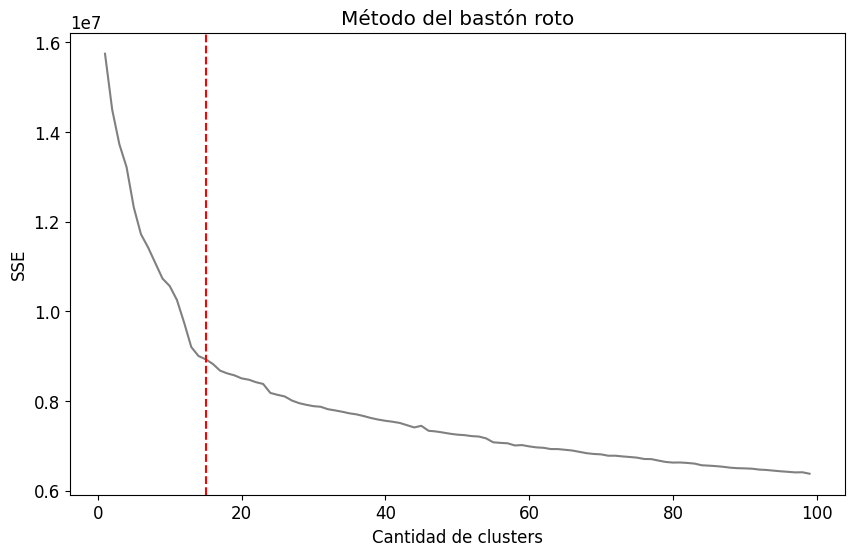

[15742327.0, 14495698.0, 13722762.0, 13215157.0, 12320188.0, 11719490.0, 11423524.0, 11076506.0, 10731514.0, 10565248.0, 10255604.0, 9752583.0, 9205948.0, 9005625.0, 8932479.0, 8828555.0, 8679759.0, 8618314.0, 8574477.0, 8506814.0, 8477504.0, 8422070.0, 8382079.0, 8182604.0, 8139760.5, 8104080.0, 8012891.0, 7954792.0, 7917641.0, 7887761.0, 7873995.0, 7820070.0, 7792967.5, 7763090.0, 7727938.0, 7704220.5, 7666183.0, 7622941.5, 7588774.5, 7561842.5, 7540461.0, 7513478.0, 7463814.0, 7413726.0, 7449332.0, 7339491.0, 7324692.0, 7299999.5, 7273201.0, 7252524.0, 7242025.5, 7220528.5, 7210554.0, 7170329.0, 7082400.0, 7069564.0, 7060315.0, 7011913.5, 7020264.0, 6991269.5, 6969160.5, 6959577.5, 6931742.5, 6930995.0, 6915178.5, 6899128.5, 6869086.5, 6839370.0, 6821993.5, 6813280.5, 6783406.0, 6783407.0, 6767339.5, 6754736.5, 6740222.0, 6710235.0, 6707447.0, 6674321.0, 6644308.0, 6630565.0, 6632612.0, 6622293.0, 6607765.5, 6570478.0, 6561944.0, 6551082.0, 6536392.0, 6515955.0, 6505248.0, 6501055.0

In [60]:
# Método del bastón roto
Baston1(100,x)

En el gráfico la línea punteada corresponde a 15 clusters, pero todavía no queda bien claro si es la cantidad óptima de grupos.

In [61]:
# Calcular SSE (Sum of Squared Errors)
sse = np.sum((x - kmeans.cluster_centers_[kmeans.labels_]) ** 2)
print("SSE:", sse)

SSE: 8909692.0


#### Validación interna

**Silhouette**

Silhouette index (promedio) para 2 clusters:  0.082
Silhouette index para el cluster 0: 0.124
Silhouette index para el cluster 1: 0.033

Silhouette index (promedio) para 3 clusters:  0.094
Silhouette index para el cluster 0: 0.042
Silhouette index para el cluster 1: 0.092
Silhouette index para el cluster 2: 0.118

Silhouette index (promedio) para 4 clusters:  0.087
Silhouette index para el cluster 0: 0.077
Silhouette index para el cluster 1: 0.03
Silhouette index para el cluster 2: 0.079
Silhouette index para el cluster 3: 0.294

Silhouette index (promedio) para 5 clusters:  0.095
Silhouette index para el cluster 0: 0.032
Silhouette index para el cluster 1: 0.055
Silhouette index para el cluster 2: 0.116
Silhouette index para el cluster 3: 0.274
Silhouette index para el cluster 4: 0.073

Silhouette index (promedio) para 6 clusters:  0.108
Silhouette index para el cluster 0: 0.026
Silhouette index para el cluster 1: 0.056
Silhouette index para el cluster 2: 0.116
Silhouette index para e

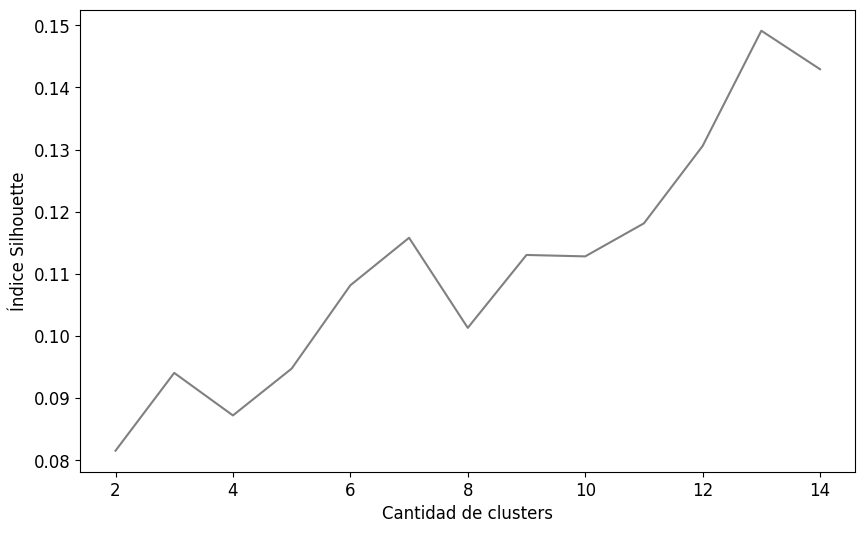

[0.08154516667127609, 0.09406748414039612, 0.08722400665283203, 0.09475907683372498, 0.10816211253404617, 0.11580437421798706, 0.10131221264600754, 0.11304289102554321, 0.11281397193670273, 0.11812879145145416, 0.13057686388492584, 0.14912129938602448, 0.14292757213115692]


In [62]:
SilIndex1(15,x)

El índice de Silhouette (en promedio) para 14 clusters es el más alto: 0.149. De todas formas, se probará con un k-means de 15.

In [63]:
# Gráfico de silhouette
def plot_sil(df,n_clusters,cluster_ids,cluster_labels,sample_silhouette_values,silhouette_avg):
    ith_cluster_silhouette_avg = []
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == cluster_ids[i]]
        ith_cluster_silhouette_avg.append(np.mean(ith_cluster_silhouette_values))
    #ith_cluster_silhouette_avg

    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(10, 6)

    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(df) + (n_clusters + 1) * 10])

    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == cluster_ids[i]]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        #color = cm.nipy_spectral(float(i) / n_clusters)
        color = cmRoyal(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        # Marcar los graficos de Silhouette con el numero de cluster
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Marcar los graficos de Silhouette con el Silhuette promedio del cluster
        ax1.text(0.6, y_lower + 0.5 * size_cluster_i, str(round(ith_cluster_silhouette_avg[i],3)))

        # Calcular donde comenzar el proximo grafixo
        y_lower = y_upper + 10 # Marco una distancia de 10 entre graficos para que haya un espacio

    ax1.set_xlabel("Coeficiente de silhouette")
    ax1.set_ylabel("Cluster label")

    # La linea vertical es el Silhouette promedio
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
    #plt.savefig(image_path+f"/../../silhouette_evaluation_plot_{maxClusters}.png")

    plt.show()
    return ith_cluster_silhouette_avg

### Ajuste con 15 clusters

In [64]:
# Estimar el coeficiente de Silhouette para cada cluster
n_clusters=15
kmeans = KMeans(n_clusters=n_clusters)
kmeans.fit(x)
cluster_ids = list(set(kmeans.labels_))
cluster_labels = kmeans.labels_
sample_silhouette_values = silhouette_samples(x,cluster_labels)
silhouette_avg = silhouette_score(x,cluster_labels)

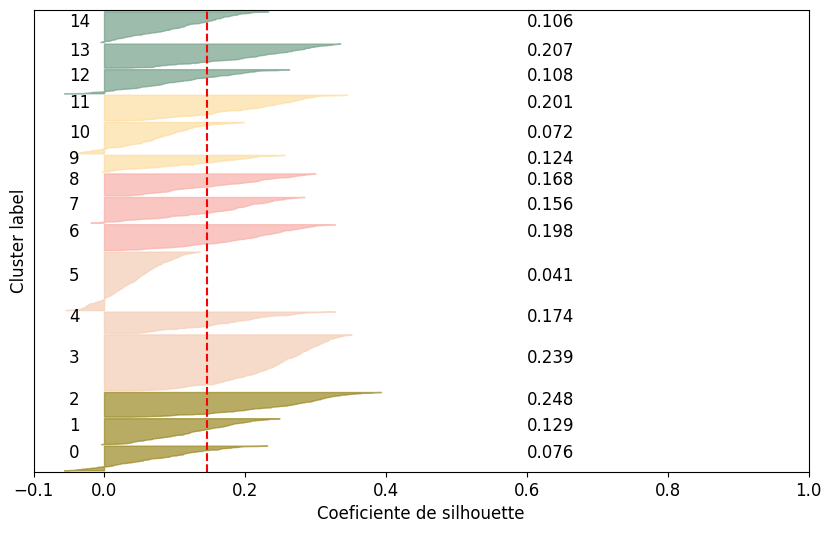

[np.float32(0.07631898),
 np.float32(0.12933399),
 np.float32(0.24819486),
 np.float32(0.23907824),
 np.float32(0.17368147),
 np.float32(0.041214455),
 np.float32(0.19815141),
 np.float32(0.1564429),
 np.float32(0.16836973),
 np.float32(0.12372574),
 np.float32(0.07170283),
 np.float32(0.20055217),
 np.float32(0.1076561),
 np.float32(0.20746207),
 np.float32(0.105990335)]

In [65]:
plot_sil(df_vectores,n_clusters,cluster_ids,cluster_labels,sample_silhouette_values,silhouette_avg)

Los valores del coeficiente de Silhouette para cada cluster son, en general, bajos (varían entre 0.04 y 0.2), lo que indica que los grupos no están claramente separados y que hay bastante solapamiento entre ellos. 

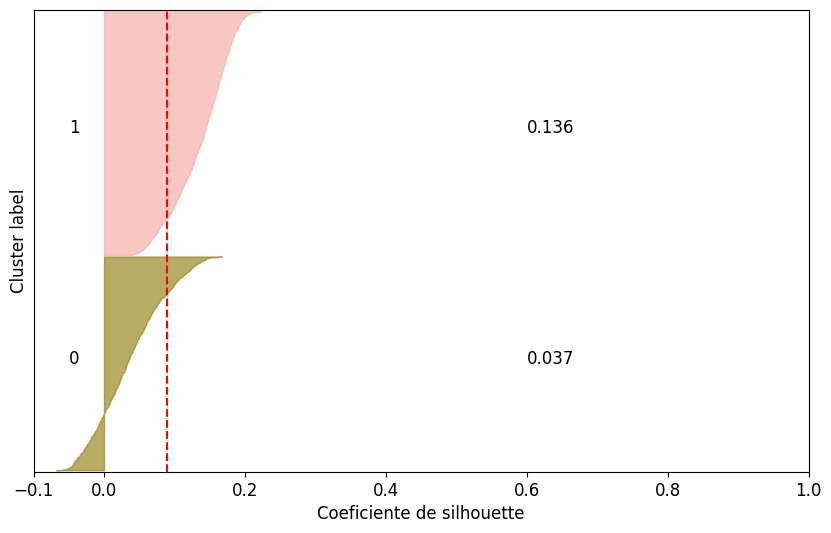

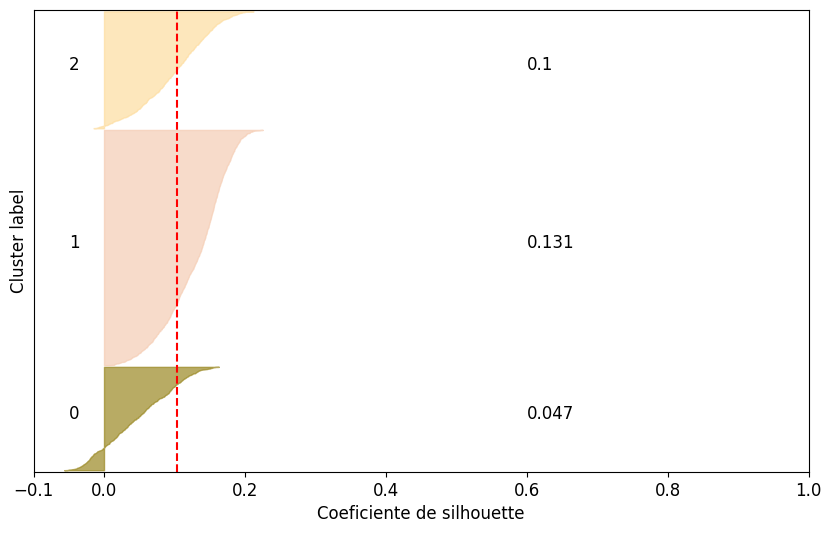

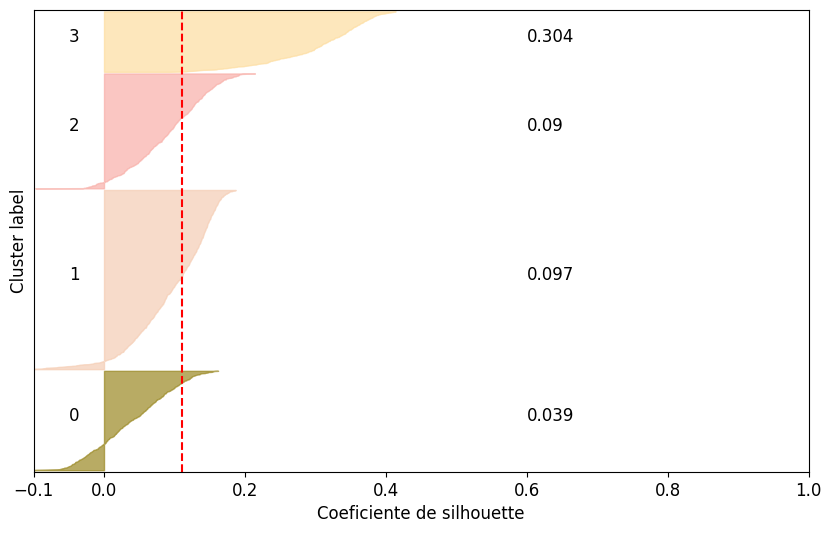

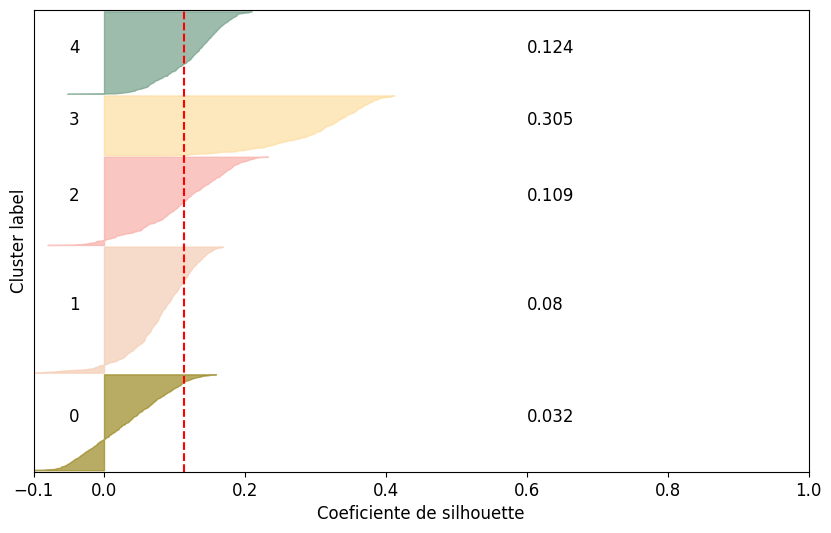

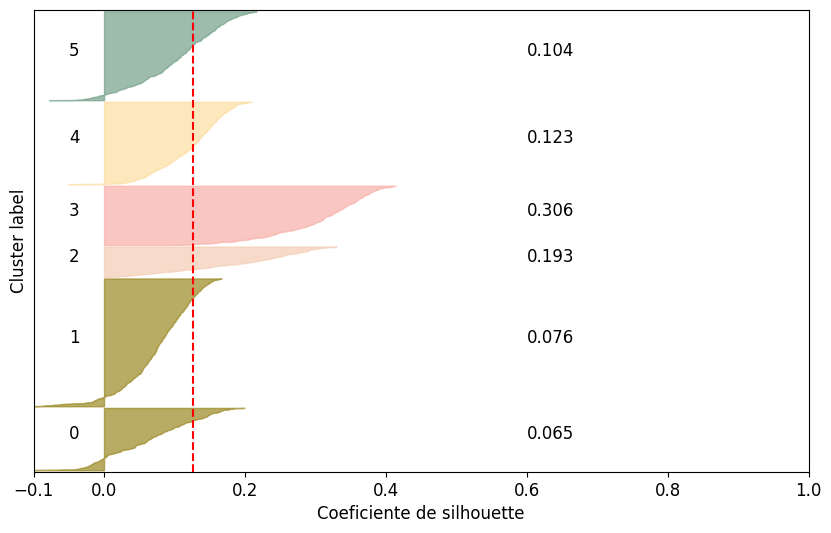

...

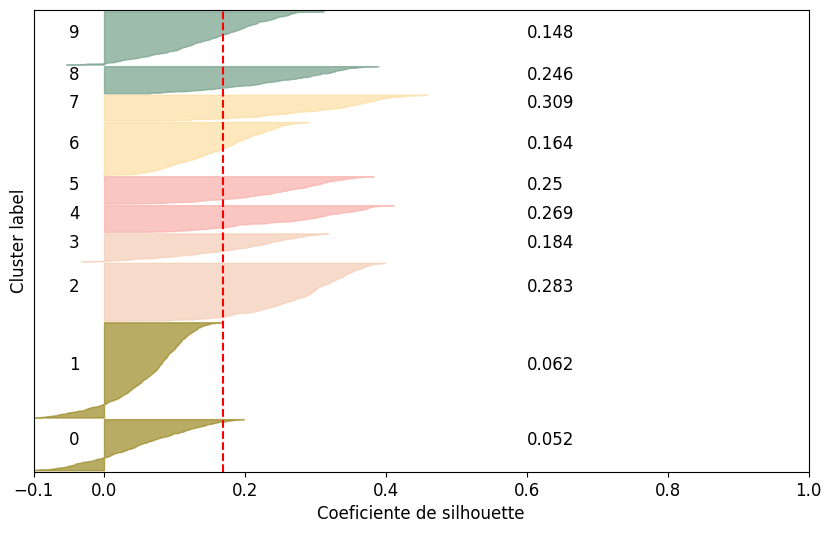

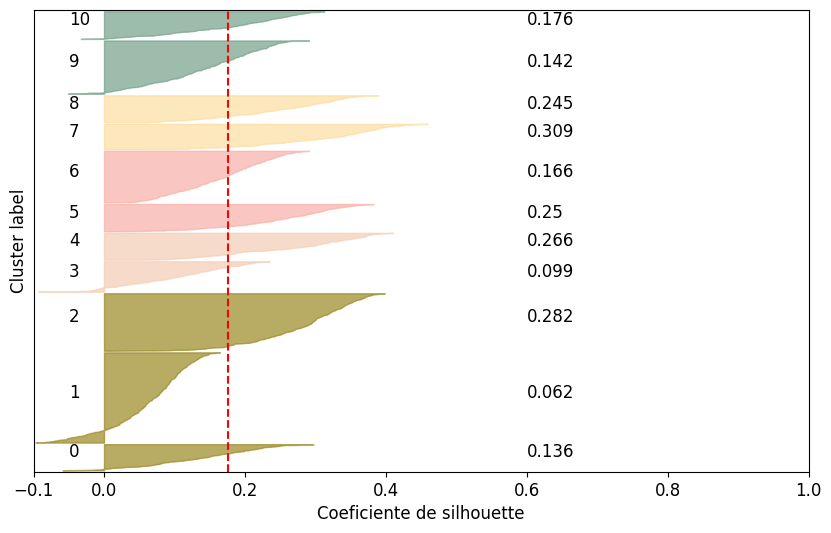

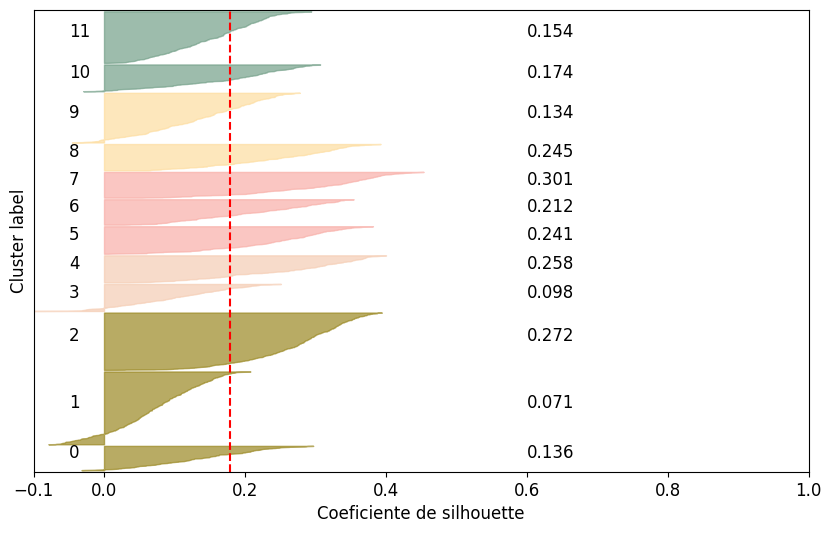

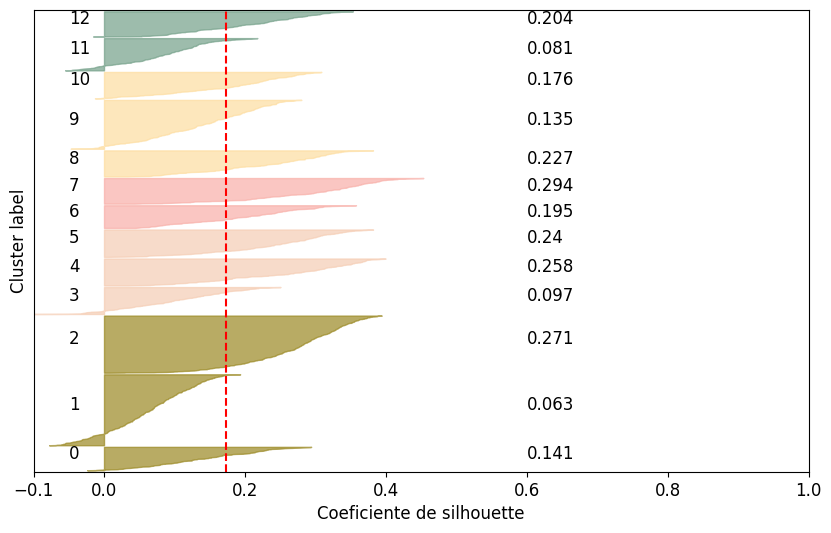

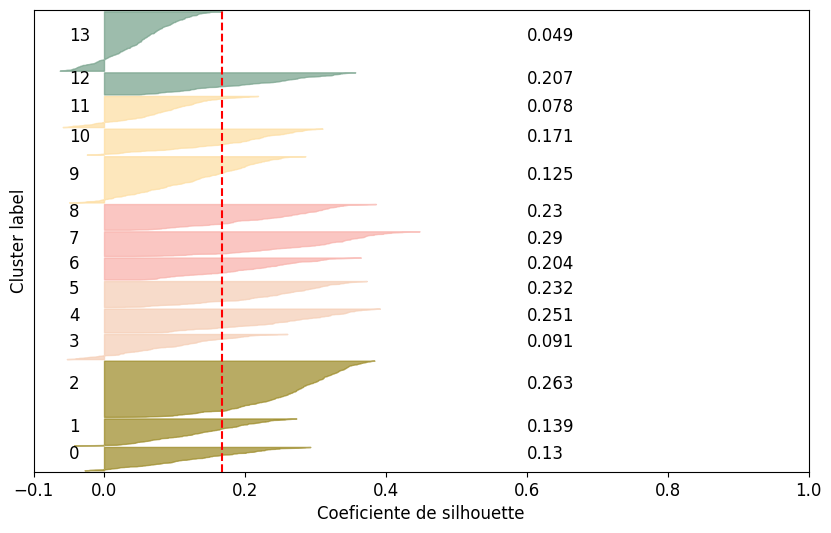

In [69]:
# Gráfico de Silhouette
GrafSil1(15,x)

#### Validación externa

##### **Matríz de confusión**

In [66]:
clase = df_vectores['Label'] # la clase

In [67]:
ctKmeans = pd.crosstab(clase,kmeans.labels_)

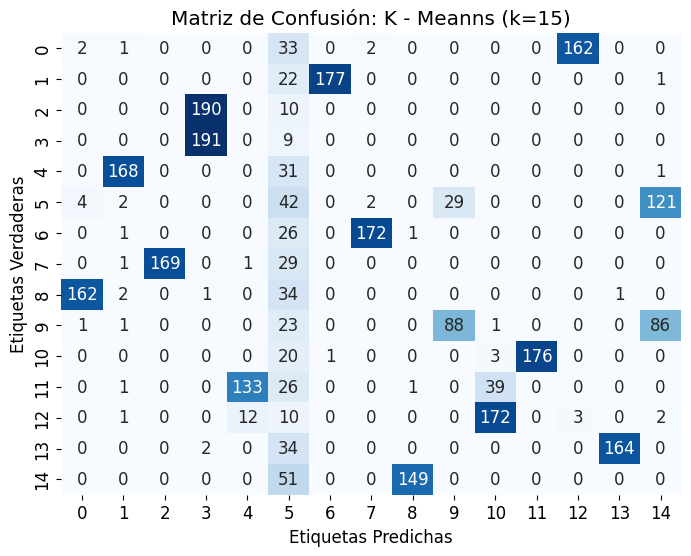

In [68]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(ctKmeans, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(15), yticklabels=range(15))
plt.xlabel('Etiquetas Predichas')
plt.ylabel('Etiquetas Verdaderas')
plt.title("Matriz de Confusión: K - Meanns (k=15)")
plt.show()

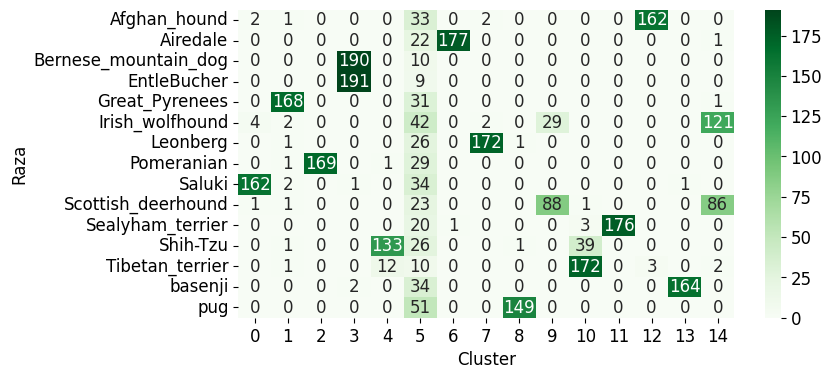

In [69]:
import seaborn as sns
plt.figure(figsize=(8,4))
sns.heatmap(ctKmeans,cmap='Greens',annot=True,fmt='g')
plt.xlabel("Cluster")
plt.ylabel("Raza")
#plt.savefig(image_path+"/../../kmeans_confusion_matrix.png")
plt.show()

En general, se observa que la mayoría de las razas tienden a concentrarse principalmente en un solo clúster (ej: Sealyham terrier y Airedale), lo que indica que el algoritmo logró agrupar correctamente muchas imágenes de la misma raza. Sin embargo, también hay casos donde las observaciones se reparten en varios clústeres, como ocurre con Shih-Tzu, Scottish deerhound y Irish wolfhound, lo que sugiere confusión o similitud visual con imágenes de otras razas.
Además, agrupó casi todas las imágenes de las razas Bernese mountain dog y EntleBucher en el mismo cluster. Si bien no son la misma raza, tiene sentido que pertenezcan al mismo grupo porque comparten un pelaje muy parecido en cuanto a colores (marrón, negro y blanco).

En el clúster 5 aparecen imágenes de todas las razas, lo que sugiere que esas fotos comparten rasgos visuales parecidos, aunque no sean de la misma raza. Probablemente el algoritmo no logró distinguir bien esas diferencias y terminó agrupando en un mismo clúster imágenes con características generales similares.

##### **Índice de Van Dongen**

In [70]:
print(f"Van Dongen para K-means: {vanDongen(ctKmeans)}")

Van Dongen para K-means: 0.2501851851851852


##### **Índice Rand Ajustado**

In [71]:
from sklearn.metrics.cluster import adjusted_rand_score
adjusted_rand_score (clase,kmeans.labels_)

0.6129009851477317

**Conclusiones**: De acuerdo con los índices de Van Dongen y Rand ajustado, el clustering K-Means identifican relativamente bien las imágenes de las distintas razas, o al menos mucho mejor que el clustering jerárquico.

## IV. K-MEDOIDS

A diferencia del algoritmo k-means, PAM opta por seleccionar un punto de los datos como centro y se basa en una métrica de distancias entre los puntos. Es más robusto ante el ruido que k-means porque minimiza la suma de disimilitudes (entre pares de puntos) en lugar de la suma de distancias euclidianas al cuadrado. De esta manera, un medoide puede definirse como el objeto de un grupo cuya disimilitud media con todos los objetos en el grupo es mínima: es el punto ubicado más hacia el centro de todo el grupo.
Al igual que con k-means, es necesario especificar el número de grupos k. Se realizó el mismo proceso de selección de k que en k-means y con el mismo objetivo de validar si el valor de k óptimo resulta cercano a la cantidad de clases de vegetales (k=15).

In [77]:
#!pip install scikit-learn-extra

In [72]:
import numpy as np
from sklearn.metrics import pairwise_distances

class KMedoids:
    def __init__(self, n_clusters=8, max_iter=300, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X):
        np.random.seed(self.random_state)
        m = X.shape[0]
        # elegimos medoids iniciales al azar
        self.medoids_ = np.random.choice(m, self.n_clusters, replace=False)
        distances = pairwise_distances(X)

        for _ in range(self.max_iter):
            # asignar cada punto al medoid más cercano
            labels = np.argmin(distances[:, self.medoids_], axis=1)
            new_medoids = np.copy(self.medoids_)

            # recalcular medoids
            for i in range(self.n_clusters):
                cluster_points = np.where(labels == i)[0]
                if len(cluster_points) == 0:
                    continue
                intra_distances = distances[np.ix_(cluster_points, cluster_points)].sum(axis=1)
                new_medoids[i] = cluster_points[np.argmin(intra_distances)]

            if np.all(new_medoids == self.medoids_):
                break
            self.medoids_ = new_medoids

        self.labels_ = labels
        self.cluster_centers_ = X[self.medoids_]
        return self

In [73]:
kmedoids = KMedoids(n_clusters=15, random_state=42)
kmedoids.fit(x)
labels = kmedoids.labels_

print("Labels:", labels)
print("Medoids:", kmedoids.medoids_)
print("Shape de centros:", kmedoids.cluster_centers_.shape)

Labels: [11 11 11 ...  8  0  8]
Medoids: [ 220 1039  725  233 2599 1117 1473 2037 2864 2406 2346   10  786 1604
 2646]
Shape de centros: (15, 200)


In [80]:
#from sklearn_extra.cluster import KMedoids

#kmedoids = KMedoids(n_clusters=15, random_state=42)
#kmedoids.fit(x)
#labels = kmedoids.labels_

In [74]:
# Calcular SSE (Sum of Squared Errors)
#sse = np.sum((x - kmedoids.cluster_centers_[kmedoids_labels]) ** 2)

medoids = kmedoids.cluster_centers_

sse = np.sum([
    np.sum((x[labels == i] - medoids[i]) ** 2)
    for i in range(len(medoids))
])

print("SSE:", sse)

SSE: 12741553.0


### Cantidad de clusters

#### Validación interna

In [75]:
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# Calcular Silhouette Score
silhouette_avg = silhouette_score(x, labels)
print("Silhouette Score:", silhouette_avg)

# Calcular Silhouette Sample Values
silhouette_values = silhouette_samples(x, labels)

Silhouette Score: 0.1088186651468277


In [76]:
# Funciones para KMedoids
# Silhouette Index: Función para calcularlo para cada número de clusters con KMedoids
def SilIndex2(maxClusters,df):
    silII = [] # lista de índice
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMedoids(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        sil_avg = silhouette_score(df, modelo.labels_) # calcular el índice Silhouette promedio de todo
        silII.append(sil_avg)
        print("Silhouette index (promedio) para "+str(i)+" clusters: ",round(sil_avg,3)) #imprime el resultado
        cluster_labels = modelo.labels_ # Las etiquetas de los clusters
        n_clusters=i # La cantidad de clusters
        sample_sil_values = silhouette_samples(df, modelo.labels_) # Los valores de SilIndex para cada registro
        for j in range(n_clusters): # Itera en la cantidad de clusters armados
            jth_cluster_sil_values = sample_sil_values[cluster_labels == j] # Los valores de SilIndex para el cluster J
            jth_cluster_sil_avg = np.mean(jth_cluster_sil_values) # El promedio de valores de SilIndex para el cluster J
            print("Silhouette index para el cluster "+str(j)+":", round(jth_cluster_sil_avg,3)) # imprime los resultados
        print() # imprime un espacio al final
    plt.plot(range(2, maxClusters), silII, color="Grey") # Gráfico
    #plt.title('Método del bastón roto')
    plt.xlabel('Cantidad de clusters')
    plt.ylabel('Índice Silhouette')
    plt.show()
    print(silII)


# Método del bastón roto: Función para realizarlo roto con el KMedoids
def Baston2(maxClusters,df):
    sse = [] # Lista de los errores
    for i in range(1, maxClusters): # Itera entre 1 y el número máximo de clusters deseados
        modelo = KMedoids(n_clusters=i, random_state=55)
        modelo.fit(df) # Fitea el modelo
        sse.append(modelo.inertia_) # Agrega el resultado a la lista
    plt.plot(range(1, maxClusters), sse, color="Grey") # Gráfico
    plt.axvline(x=20,ymin=0,ymax=1,c="r",linestyle="--")
    plt.title('Método del bastón roto - KMedoids')
    plt.xlabel('Cantidad de clusters')
    plt.ylabel('SSE')
    #plt.savefig(image_path+f"/../../PAM_elbow_plot_{maxClusters}.png")
    plt.show()

    print(sse)


# Gráfico de Silhouette: función para graficarlo por cada número de clusters con KMedoids
def GrafSil2(maxClusters,df):
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMedoids(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        sil_avg = silhouette_score(df, modelo.labels_) # calcular el índice Silhouette promedio de todo

        cluster_labels = modelo.labels_ # Las etiquetas de los clusters
        n_clusters=i # La cantidad de clusters
        sample_sil_values = silhouette_samples(df, modelo.labels_)

        fig, ax1 = plt.subplots(1, 1)
        fig.set_size_inches(10, 6)

        ax1.set_xlim([-0.1, 1])
        ax1.set_ylim([0, len(df) + (n_clusters + 1) * 10])

        y_lower = 10
        for j in range(n_clusters):
            jth_cluster_sil_values = sample_sil_values[cluster_labels == j]
            jth_cluster_sil_avg = np.mean(jth_cluster_sil_values)
            jth_cluster_sil_values.sort()
            size_cluster_j = jth_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_j

            #color = cm.nipy_spectral(float(j) / n_clusters)
            color = cmRoyal(float(j) / n_clusters)
            ax1.fill_betweenx(np.arange(y_lower, y_upper),
                              0, jth_cluster_sil_values,
                              facecolor=color, edgecolor=color, alpha=0.7)

            # Marcar los graficos de Silhouette con el numero de cluster
            ax1.text(-0.05, y_lower + 0.5 * size_cluster_j, str(j))

            # Marcar los graficos de Silhouette con el Silhuette promedio del cluster
            ax1.text(0.6, y_lower + 0.5 * size_cluster_j, str(round(jth_cluster_sil_avg,3)))

            # Calcular donde comenzar el proximo grafixo
            y_lower = y_upper + 10 # Marco una distancia de 10 entre graficos para que haya un espacio

        ax1.set_xlabel("Coeficiente de silhouette")
        ax1.set_ylabel("Cluster label")

        # La linea vertical es el Silhouette promedio
        ax1.axvline(x=sil_avg, color="red", linestyle="--")

        ax1.set_yticks([])
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        #plt.savefig(image_path+f"/../../PAM_silhouette_plot_{maxClusters}.png")
        plt.show()



# Adjusted Rand Index: función para calcularlo para cada número de clusters con KMeans
def RandIndex2(maxClusters,df,classes):
    for i in range(2, maxClusters): # itera entre 2 y el número de clusters máximo establecido
        modelo = KMedoids(n_clusters=i, random_state=55).fit(df) # aplica el modelo deseado
        ari = adjusted_rand_score(classes, modelo.labels_) # calcula el índice Rand
        print("Rand index para "+str(i)+" clusters: ",round(ari,3)) #imprime el resultado


# Van Dongen: función para calcular el índice de Van Dongen para cada número de clusters con KMeans
def VDIndex2(maxClusters,df):
    for i in range(2, maxClusters): # Itera entre 1 y el número máximo de clusters deseados
        modelo = KMedoids(n_clusters=i, random_state=55).fit(df)
        cluster_labels = modelo.labels_
        tmp = pd.DataFrame({'Labels': clase, 'Clusters': modelo.labels_})# Crear un DataFrame con Labels y Clusters como columnas
        ct = pd.crosstab(tmp['Labels'], tmp['Clusters']) # Crea una matriz de confusion
        VD = vanDongen(ct)
        print("Van Dongen index para "+str(i)+" clusters: ",round(VD,3))

Silhouette index (promedio) para 2 clusters:  0.094
Silhouette index para el cluster 0: 0.125
Silhouette index para el cluster 1: 0.088

Silhouette index (promedio) para 3 clusters:  0.094
Silhouette index para el cluster 0: 0.294
Silhouette index para el cluster 1: 0.108
Silhouette index para el cluster 2: 0.037

Silhouette index (promedio) para 4 clusters:  0.089
Silhouette index para el cluster 0: 0.21
Silhouette index para el cluster 1: 0.089
Silhouette index para el cluster 2: 0.018
Silhouette index para el cluster 3: 0.219

Silhouette index (promedio) para 5 clusters:  0.107
Silhouette index para el cluster 0: 0.276
Silhouette index para el cluster 1: 0.061
Silhouette index para el cluster 2: 0.025
Silhouette index para el cluster 3: 0.241
Silhouette index para el cluster 4: 0.293

Silhouette index (promedio) para 6 clusters:  0.103
Silhouette index para el cluster 0: 0.271
Silhouette index para el cluster 1: 0.024
Silhouette index para el cluster 2: 0.016
Silhouette index para e

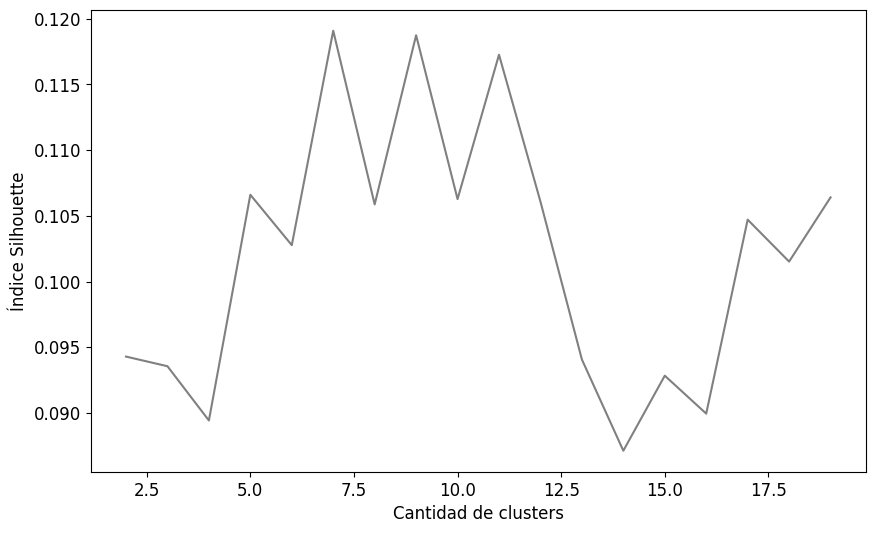

[0.09428759664297104, 0.09355311840772629, 0.08942482620477676, 0.10660117864608765, 0.10276661068201065, 0.11908384412527084, 0.10586842894554138, 0.1187380775809288, 0.10627061873674393, 0.1172572448849678, 0.10608299821615219, 0.09406846761703491, 0.08712375909090042, 0.09283421188592911, 0.08994602411985397, 0.10470689833164215, 0.10151568800210953, 0.10640177130699158]


In [81]:
SilIndex2(20,x)

En general los coeficientes de Sillouette son muy cercanos a cero, lo cual indica que se superponen los grupos.

### Ajuste con 15 clusters 

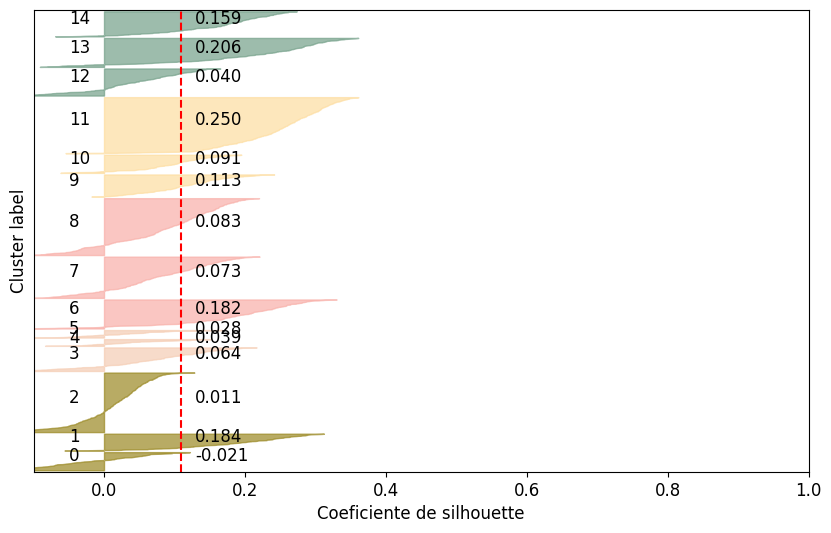

In [77]:
def plot_silhouette(X, labels):
    import numpy as np
    from sklearn.metrics import silhouette_samples, silhouette_score

    n_clusters = len(np.unique(labels))
    cluster_ids = np.sort(np.unique(labels))
    sil_vals = silhouette_samples(X, labels)
    sil_avg = silhouette_score(X, labels)

    fig, ax1 = plt.subplots(figsize=(10,6))
    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(sil_vals) + (n_clusters + 1) * 10])

    y_lower = 10
    for i, cid in enumerate(cluster_ids):
        vals = np.sort(sil_vals[labels == cid])
        size = vals.shape[0]
        y_upper = y_lower + size

        color = cmRoyal(i / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                          facecolor=color, edgecolor=color, alpha=0.7)

        ax1.text(-0.05, y_lower + 0.5*size, str(cid))
        ax1.text(min(0.02 + sil_avg, 0.95), y_lower + 0.5*size, f"{vals.mean():.3f}")
        y_lower = y_upper + 10

    ax1.axvline(x=sil_avg, color="red", linestyle="--")
    ax1.set_xlabel("Coeficiente de silhouette")
    ax1.set_ylabel("Cluster label")
    ax1.set_yticks([])
    plt.show()

# Uso:
plot_silhouette(x, kmedoids.labels_)


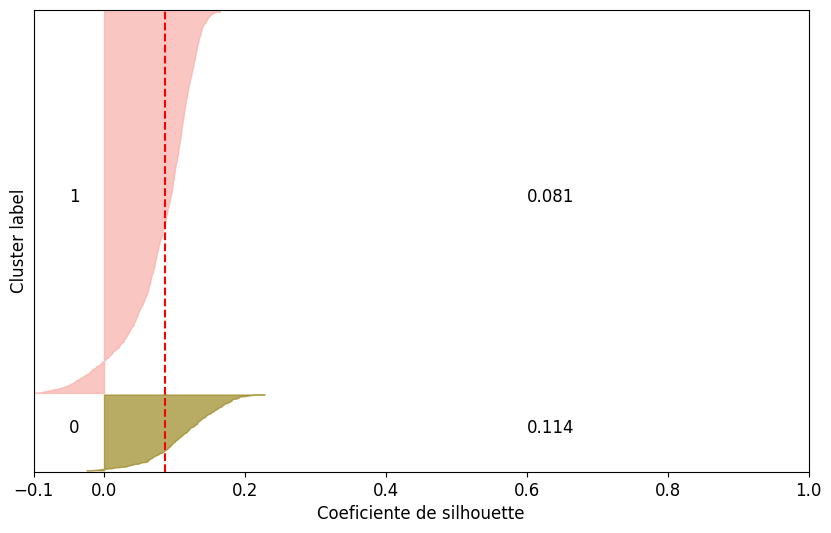

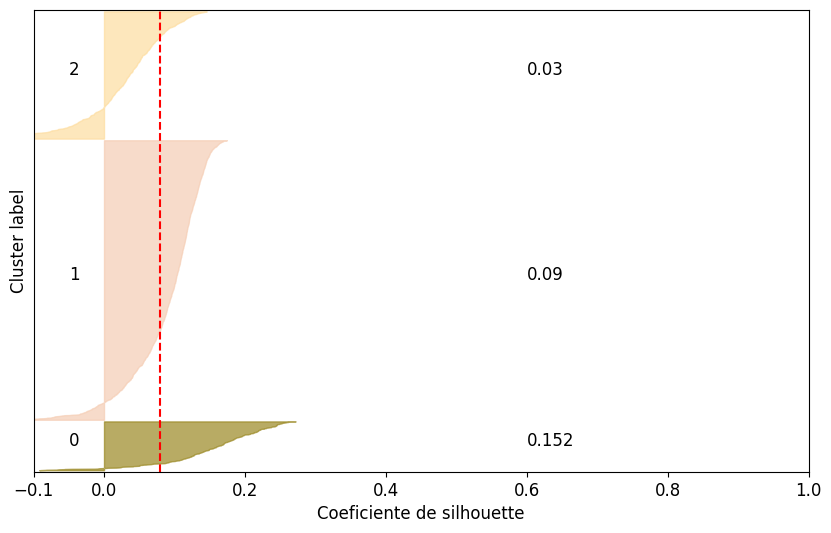

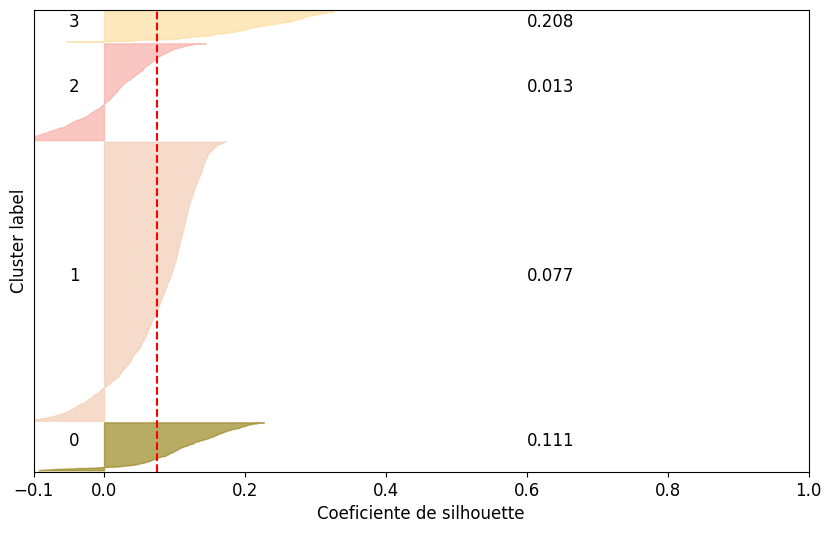

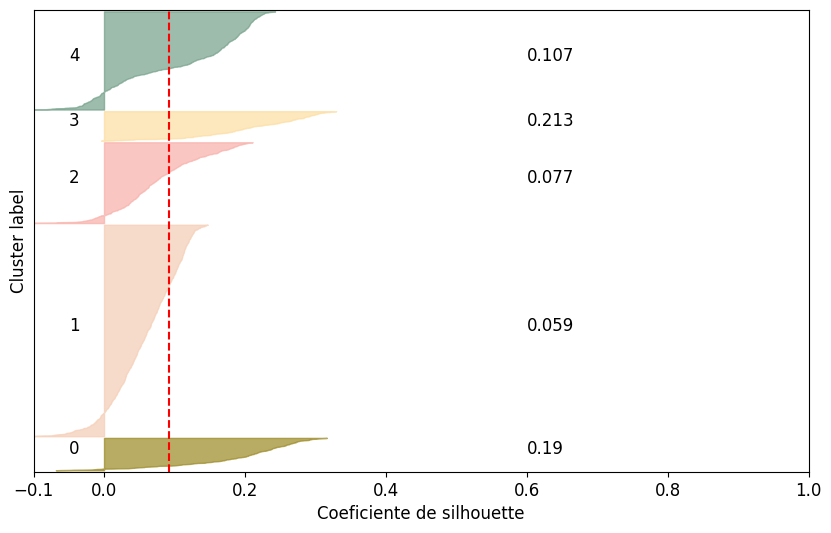

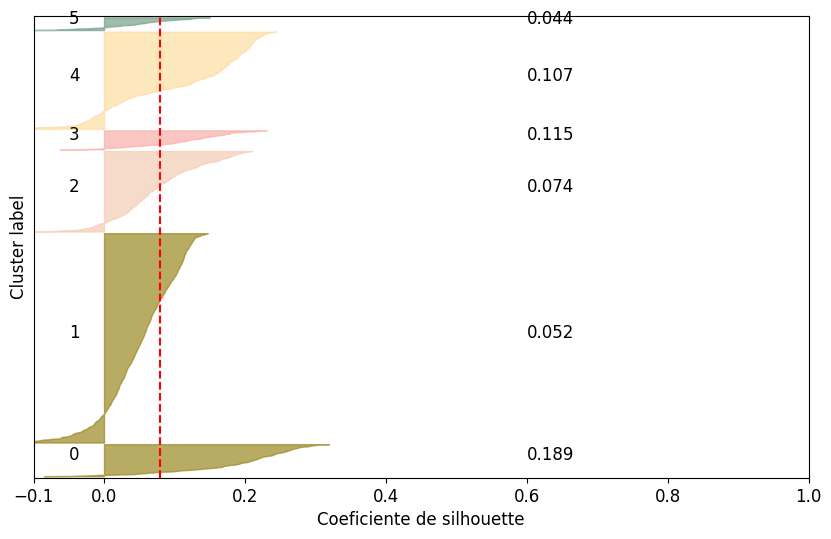

...

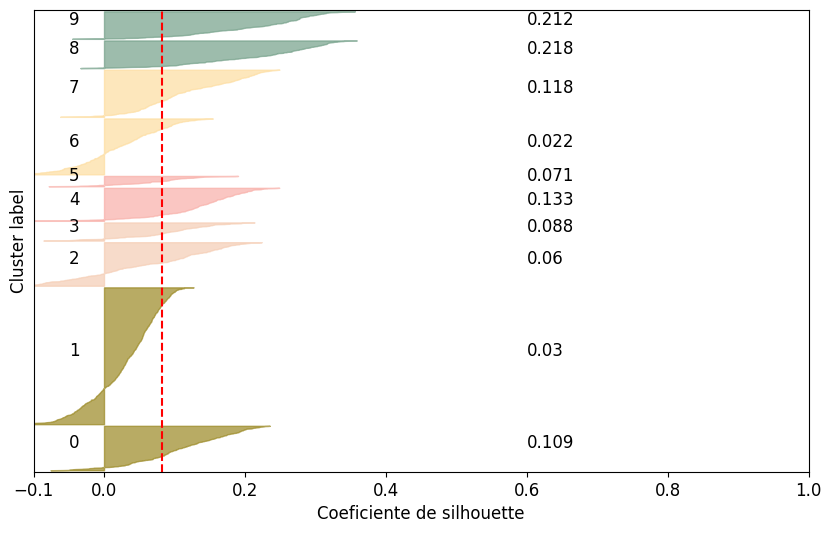

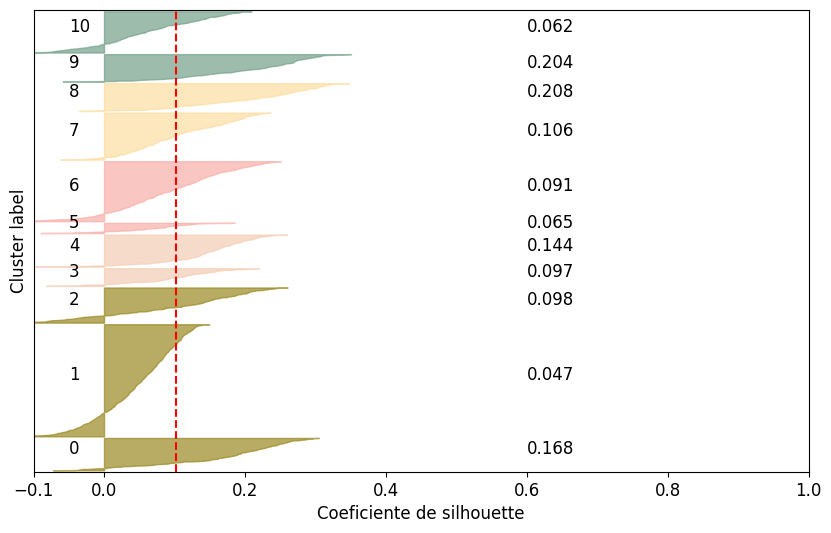

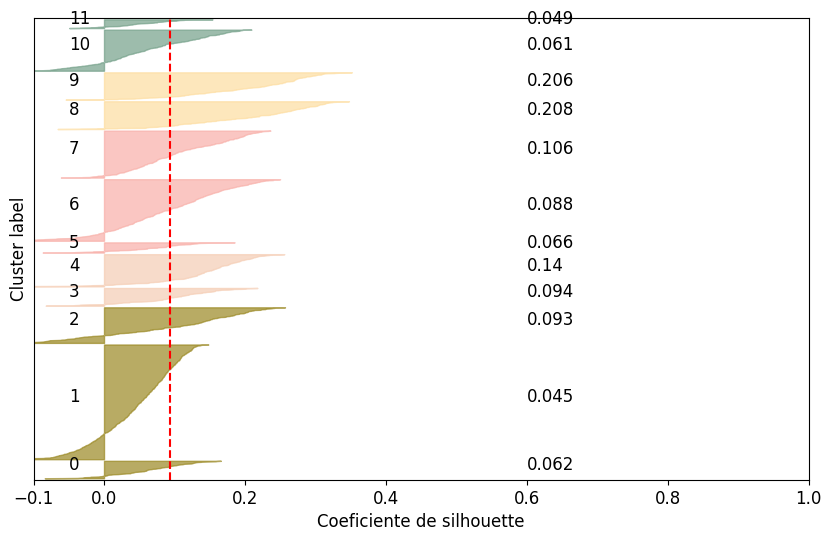

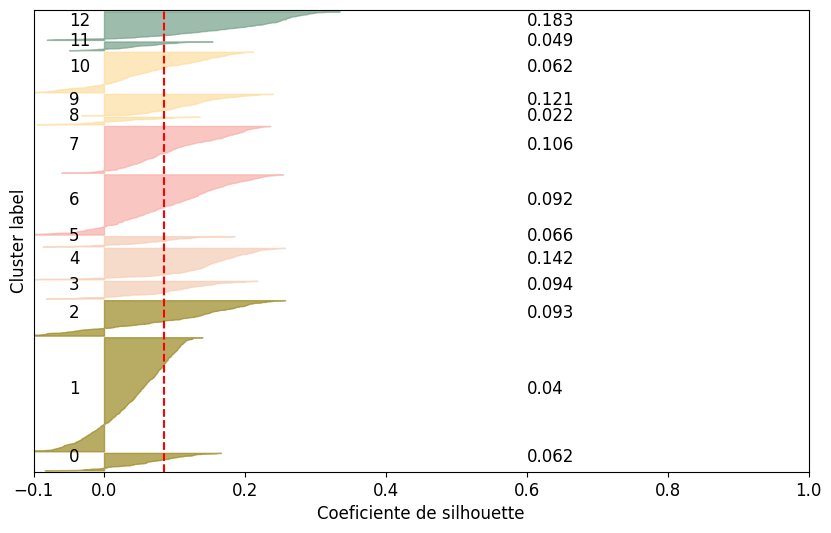

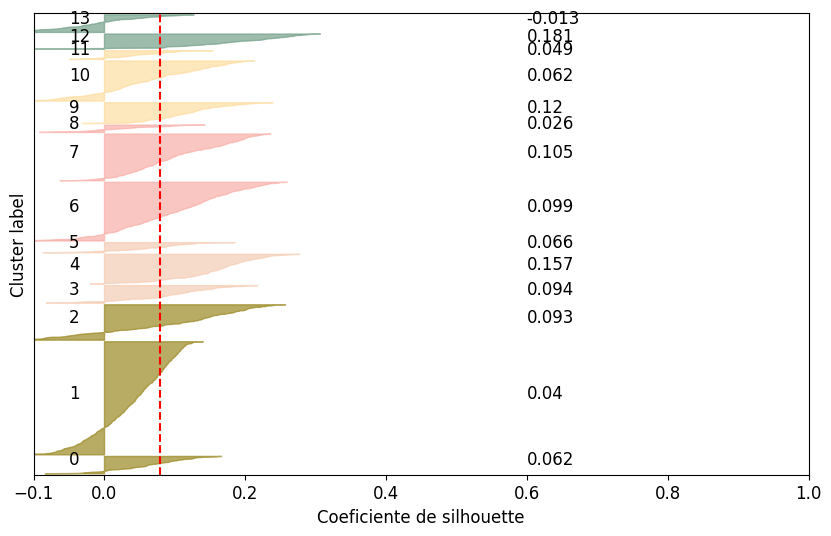

In [78]:
# Gráfico de Silhouette
GrafSil2(15,x)

#### Validación externa

##### **Matríz de confusión**

In [79]:
ctKmedoids = pd.crosstab(clase,labels)

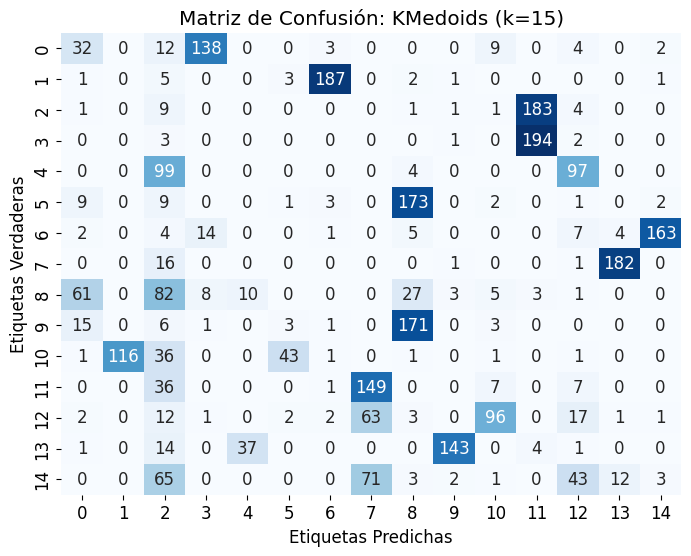

In [80]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(ctKmedoids, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(15), yticklabels=range(15))
plt.xlabel('Etiquetas Predichas')
plt.ylabel('Etiquetas Verdaderas')
plt.title("Matriz de Confusión: KMedoids (k=15)")
plt.show()

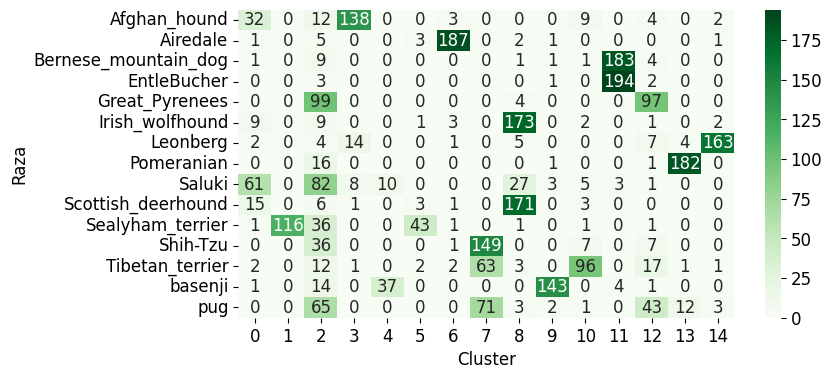

In [81]:
import seaborn as sns
plt.figure(figsize=(8,4))
sns.heatmap(ctKmedoids,cmap='Greens',annot=True,fmt='g')
plt.xlabel("Cluster")
plt.ylabel("Raza")
#plt.savefig(image_path+"/../../kmedoids_confusion_matrix.png")
plt.show()

##### **Índice de Van Dongen**

In [82]:
print(f"Van Dongen para K-medoids: {vanDongen(ctKmedoids)}")

Van Dongen para K-medoids: 0.3662833827893175


##### **Índice Rand Ajustado**

In [83]:
adjusted_rand_score (clase,labels)

0.48365505607898296

**Conclusiones**: Esta metodología agrupa peor que el K-Means pero mejor que el clustering jerárquico. En el cluster "2" se agrupan imágenes de todas las razas, al igual que pasó usando k-means. También se clasifican en el cluster "11" casi todas las observaciones de las razas Bernese Mountain Dog y Entle Butcher.

## V. CLUSTERING BASADO EN DENSIDAD

RangeIndex(start=0, stop=200, step=1)


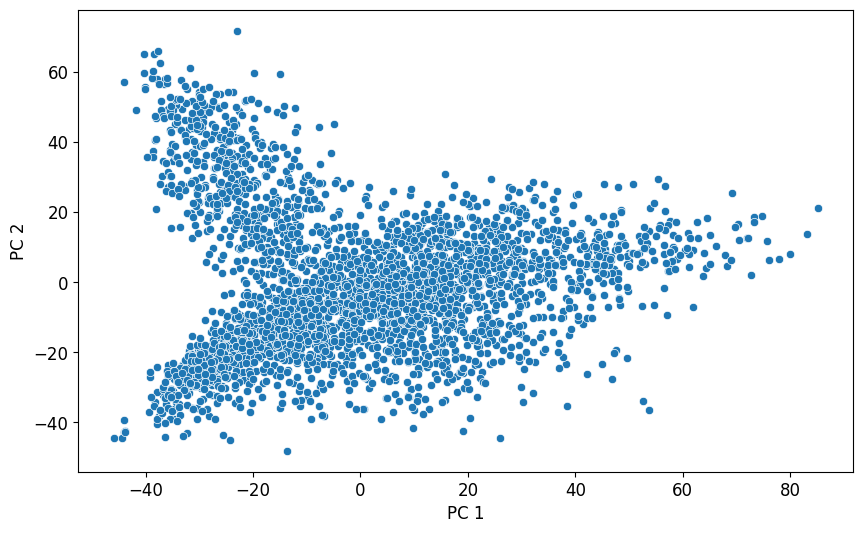

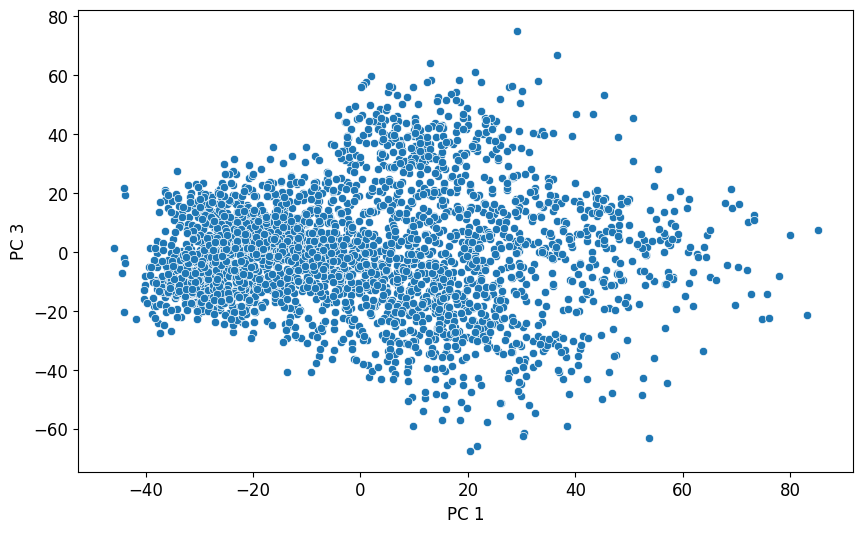

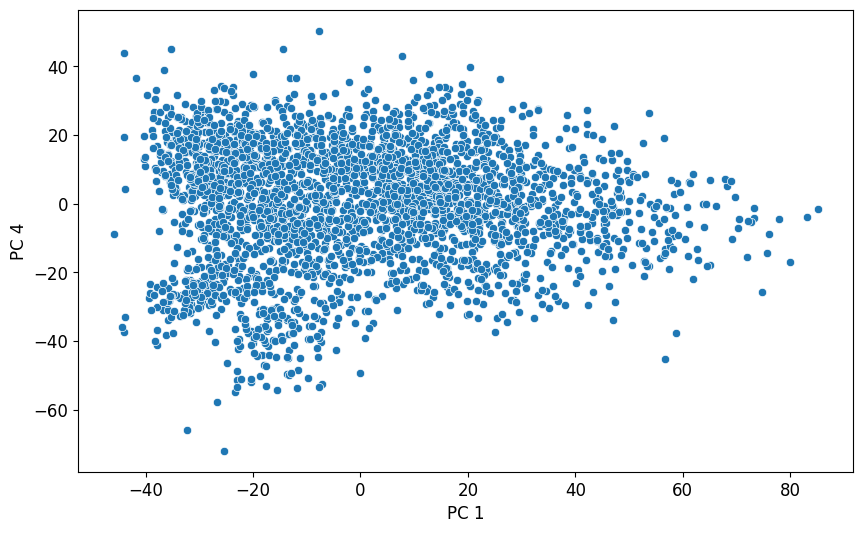

In [84]:
import seaborn as sns
data=pd.DataFrame(x)
print(data.columns)
palette=sns.color_palette()
sns.set_palette(sns.color_palette())
sns.scatterplot(x=0,y=1,data=data)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()
sns.scatterplot(x=0,y=2,data=data)
plt.xlabel("PC 1")
plt.ylabel("PC 3")
plt.show()
sns.scatterplot(x=0,y=3,data=data)
plt.xlabel("PC 1")
plt.ylabel("PC 4")
plt.show()

# Revisar epsilon óptimo

In [85]:
import sklearn
import matplotlib.pyplot as plt
clase = df_vectores['Label']

for j in range(5,150,5):
  for n,epsilons in enumerate(range(10,100,2)):
    DBscan=sklearn.cluster.DBSCAN(eps=epsilons,
                                  min_samples=j,
                                  metric='euclidean',
                                  metric_params=None,
                                  algorithm='auto',
                                  leaf_size=10,
                                  p=None,
                                  n_jobs=None)
    DBscan.fit(x)
    ctDBscan = pd.crosstab(clase,DBscan.labels_)
    vd=vanDongen(ctDBscan)
    if 20>len(set((DBscan.labels_))) and 0.65>vd:
      print(f"{vd:2f} para eps= {epsilons} y nmin {j} usando {len(set((DBscan.labels_)))} clusters")




# Reemplazar por el óptimo

Index([       0,        1,        2,        3,        4,        5,        6,
              7,        8,        9,
       ...
            191,      192,      193,      194,      195,      196,      197,
            198,      199, 'labels'],
      dtype='object', length=201)


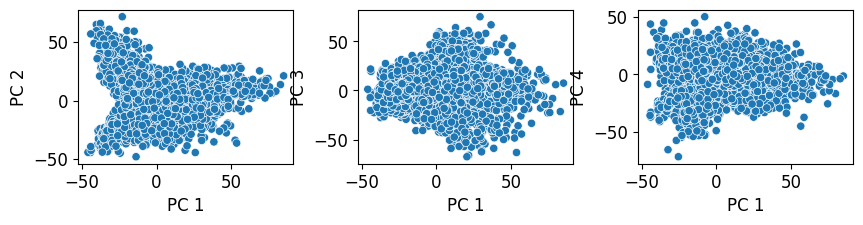

In [86]:
import sklearn
DBscan=sklearn.cluster.DBSCAN(eps=34,
                              min_samples=20,
                              metric='euclidean',
                              metric_params=None,
                              algorithm='auto',
                              leaf_size=100,
                              p=None,
                              n_jobs=None)
DBscan.fit(x)

import seaborn as sns
data=pd.DataFrame(x)
data['labels']=DBscan.labels_
print(data.columns)
palette=sns.color_palette()
sns.set_palette(sns.color_palette())
fig,ax=plt.subplots(1,3,figsize=(10,2),)
fig.subplots_adjust(wspace=0.3)
sns.scatterplot(x=0,y=1,data=data,hue="labels",palette=palette,ax=ax[0])
ax[0].set_xlabel("PC 1")
ax[0].set_ylabel("PC 2")
ax[0].get_legend().remove()
sns.scatterplot(x=0,y=2,data=data,hue="labels",palette=palette,ax=ax[1])
ax[1].set_xlabel("PC 1")
ax[1].set_ylabel("PC 3")
ax[1].get_legend().remove()
sns.scatterplot(x=0,y=3,data=data,hue="labels",palette=palette,ax=ax[2])
ax[2].set_xlabel("PC 1")
ax[2].set_ylabel("PC 4")
ax[2].get_legend().remove()


#### Validación externa

##### **Matríz de confusión**

In [87]:
clase = df_vectores['Label'] # la clase

In [88]:
ctDBscan = pd.crosstab(clase,DBscan.labels_)

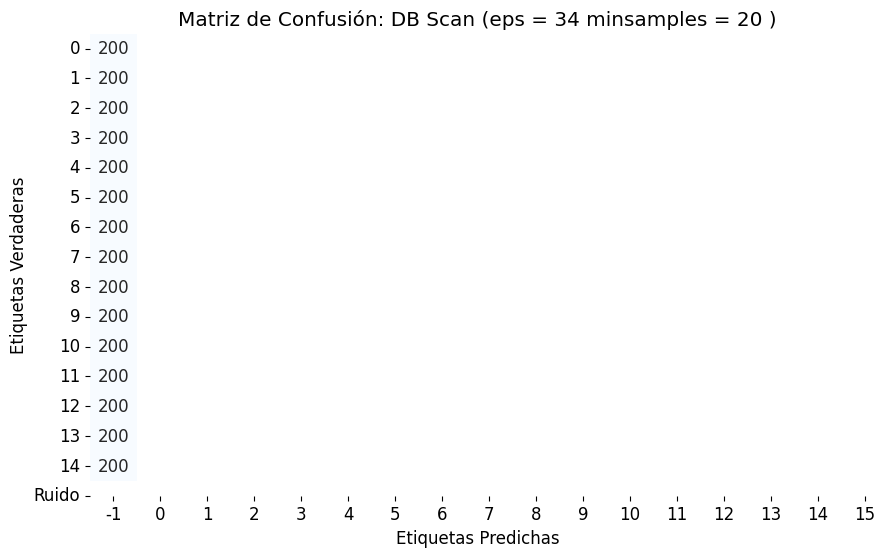

In [89]:
import seaborn as sns
labels_matrix=["0","1","2","3","4","5","6","7","8","9","10","11","12","13","14","Ruido"]
plt.figure(figsize=(10, 6))
sns.heatmap(ctDBscan, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(-1,16), yticklabels=labels_matrix
            )
plt.xlabel('Etiquetas Predichas')
plt.ylabel('Etiquetas Verdaderas')
plt.title("Matriz de Confusión: DB Scan (eps = 34 minsamples = 20 )")
plt.show()

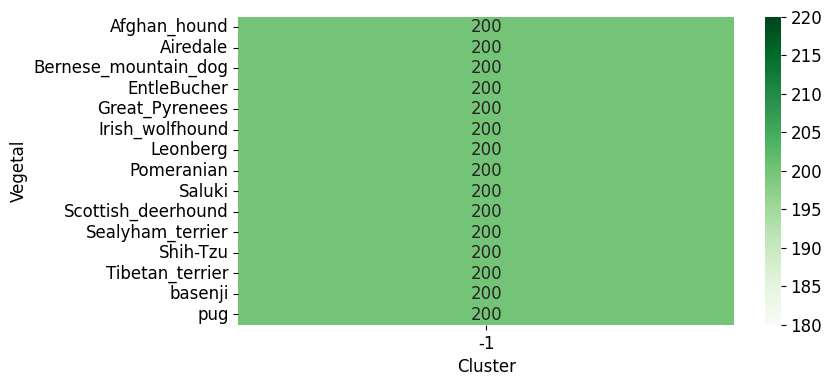

In [90]:
import seaborn as sns
plt.figure(figsize=(8,4))
sns.heatmap(ctDBscan,cmap='Greens',annot=True,fmt='g')
plt.xlabel("Cluster")
plt.ylabel("Vegetal")
#plt.savefig(image_path+"/../../DBscan_confusion_matrix.png")
plt.show()

##### **Índice de Van Dongen**

In [91]:
print(f"Van Dongen para DB Scan: {vanDongen(ctDBscan)}")

Van Dongen para DB Scan: 1.0


##### **Índice Rand Ajustado**

In [92]:
from sklearn.metrics.cluster import adjusted_rand_score
adjusted_rand_score (clase,DBscan.labels_)

0.0

Como era de esperar, el método de clustering basado en densidad no logró diferenciar las imágenes por raza, sino que agrupó todas dentro de un mismo clúster. Esto era previsible, ya que en los otros métodos de agrupamiento ya se observaba un grupo que reunía imágenes de distintas razas con características visuales similares.

**Conclusiones finales**: El clustering jerárquico fue el que peor desempeño tuvo, mientras que K-Means logró resultados bastante mejores, identificando patrones más coherentes entre razas. El K-Medoids no fue tan bueno como el K-Means pero sí mejor que el jerárquico o clustering basado en densidad, ya que tuvo algunos aciertos pero también confusión entre grupos. Finalmente, el clustering basado en densidad no distinguió las imágenes y las agrupó todas como un único conjunto.